
**Enhanced visualization and evidence-audit edition**
# HAMV-CC — In-Depth Reproducible Research Notebook

**Heterogeneity-Aware Multi-View Contrastive Clustering for Incomplete Scanned Document Archives**

This notebook is designed as a **research/evidence harness**, not merely a demonstration script. It contains:

1. source-level archive discovery and SHA-256 manifesting;
2. fixed-resolution image ingestion;
3. median filtering, contour-based deskewing, CLAHE and optional binarization;
4. the 16-dimensional handcrafted descriptor used in the supplied validation workflow;
5. optional ImageNet-pretrained ResNet50 features (first 100 dimensions);
6. standardization + PCA;
7. feature-space Gaussian-noise contrastive learning with NT-Xent;
8. an eight-method clustering registry;
9. majority-vote cluster-count selection;
10. a stability-aware cluster-count criterion;
11. internal metrics and external-label metrics;
12. missing-view stress tests;
13. controlled scan-degradation tests;
14. a hard synthetic incomplete multi-view fixture;
15. an **executable research extension** implementing view-specific encoders, availability/reliability gating, cross-view consistency, cluster consistency, and instance contrast;
16. repeated-seed experiments and ablation scaffolding;
17. plots, CSV evidence outputs, and an environment ledger.
18. **end-to-end archive clustering** with representation/algorithm comparison, cluster-count diagnostics and bootstrap stability (Section 21);
19. **cluster visualization suite**: embeddings, silhouette knife plots, feature profiles, dendrogram, co-association, image montages.

### Evidence boundary

The supplied manuscript distinguishes the **implemented baseline** from the **proposed full HAMV-CC objective**. This notebook preserves that distinction.

- The archive pipeline and feature-space SSL path reproduce the source-aligned implementation.
- The full reliability-gated HAMV-CC module below is an executable research extension for completing the proposed evaluation.
- Running the extension does **not** make the manuscript's already-reported numbers true for the new implementation; new results must be logged and reported from actual execution.
- Internal clustering metrics are treated as geometric diagnostics, not semantic ground truth.
- Heuristic document-type descriptions are auxiliary evidence only.



## 0. Reproducibility contract

Before a confirmatory run:

- freeze the dataset manifest;
- freeze preprocessing switches;
- freeze feature ordering;
- freeze representation hyperparameters;
- freeze candidate `k` range;
- predeclare seeds;
- keep failed runs in the ledger;
- use matched seeds for representation comparisons;
- do not use heuristic labels to tune the representation;
- keep public benchmark test labels untouched until all choices are frozen.

The private archive used in the supplied evidence contained **683 raster files: 651 JPEG and 32 TIFF**, with **8 duplicate SHA-256 groups**. The values are reference observations from the supplied validation execution; rerunning this notebook on a different archive should report the newly observed counts rather than assuming them.


In [1]:

# 1. Environment / dependency setup
# ------------------------------------------------------------
# Recommended packages:
# numpy pandas scipy scikit-learn opencv-python pillow matplotlib
# torch torchvision nbformat psutil
#
# Optional:
# pymupdf python-docx
#
# Install from a terminal if needed:
#   python -m pip install numpy pandas scipy scikit-learn opencv-python pillow matplotlib torch torchvision psutil pymupdf python-docx

import os, sys, json, math, time, random, hashlib, platform, warnings, subprocess
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

print("Python:", sys.version)
print("Platform:", platform.platform())


Python: 3.8.10 (tags/v3.8.10:3d8993a, May  3 2021, 11:48:03) [MSC v.1928 64 bit (AMD64)]
Platform: Windows-10-10.0.26200-SP0


In [2]:

# 2. Core scientific imports and deterministic utilities
import cv2
import matplotlib.pyplot as plt

from scipy.optimize import linear_sum_assignment
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import (
    KMeans, MiniBatchKMeans, AgglomerativeClustering,
    DBSCAN, SpectralClustering, AffinityPropagation
)
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score, calinski_harabasz_score, davies_bouldin_score,
    adjusted_rand_score, normalized_mutual_info_score,
    confusion_matrix, f1_score
)
from sklearn.manifold import TSNE

try:
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
    TORCH_AVAILABLE = True
except Exception as e:
    TORCH_AVAILABLE = False
    print("PyTorch unavailable:", e)

SEED_DEFAULT = 42

def seed_everything(seed=SEED_DEFAULT):
    random.seed(seed)
    np.random.seed(seed)
    if TORCH_AVAILABLE:
        torch.manual_seed(seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)

seed_everything(SEED_DEFAULT)

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Torch:", getattr(torch, "__version__", "not installed"))
print("CUDA:", torch.cuda.is_available() if TORCH_AVAILABLE else False)


NumPy: 1.24.3
Pandas: 2.0.3
Torch: 2.4.1+cu124
CUDA: True


In [3]:

# 3. Frozen experiment configuration
CONFIG = {
    "work_size": (224, 224),
    "pdf_dpi": 200,
    "use_denoise": True,
    "use_deskew": True,
    "use_clahe": True,
    "use_binarize": False,

    "use_resnet50": True,
    "visual_dims": 100,
    "pca_target": 50,
    "use_pca": True,

    "ssl_epochs": 30,
    "ssl_lr": 1e-3,
    "ssl_weight_decay": 1e-5,
    "ssl_temperature": 0.1,
    "ssl_projection_dim": 128,
    "ssl_batch_size": 32,
    "ssl_sigma_start": 0.12,
    "ssl_sigma_end": 0.02,
    "ssl_grad_clip": 1.0,

    "k_min": 2,
    "k_max": 20,
    "matched_seeds": list(range(10)),

    "consensus_resamples": 15,
    "consensus_fraction": 0.80,

    "synthetic_n": 180,
    "synthetic_k": 3,
    "dbscan_eps": None,   # None = adaptive (90th percentile of 3-NN distance); set 1.0 to reproduce the legacy fixed eps
}

CANDIDATE_ROOTS = ([Path(os.environ["HAMVCC_DATASET"])] if os.environ.get("HAMVCC_DATASET") else []) + [
    Path.home() / "OneDrive" / "Desktop" / "NEW_MODEL" / "NEW" / "HAMV_CC_DATA" / "dataset" / "dataset",
    Path.cwd() / "dataset",
    Path.cwd() / "data",
]

OUT_DIR = Path.cwd() / "hamvcc_runs" / datetime.now().strftime("%Y%m%d_%H%M%S")
OUT_DIR.mkdir(parents=True, exist_ok=True)

with open(OUT_DIR / "frozen_config.json", "w", encoding="utf-8") as f:
    json.dump(CONFIG, f, indent=2, default=str)

print("Output:", OUT_DIR.resolve())
print(json.dumps(CONFIG, indent=2))


Output: C:\Users\Debmalya Ray\OneDrive\Desktop\NEW_MODEL\NEW_FOLDER_03_10_2026\hamvcc_runs\20261004_205633
{
  "work_size": [
    224,
    224
  ],
  "pdf_dpi": 200,
  "use_denoise": true,
  "use_deskew": true,
  "use_clahe": true,
  "use_binarize": false,
  "use_resnet50": true,
  "visual_dims": 100,
  "pca_target": 50,
  "use_pca": true,
  "ssl_epochs": 30,
  "ssl_lr": 0.001,
  "ssl_weight_decay": 1e-05,
  "ssl_temperature": 0.1,
  "ssl_projection_dim": 128,
  "ssl_batch_size": 32,
  "ssl_sigma_start": 0.12,
  "ssl_sigma_end": 0.02,
  "ssl_grad_clip": 1.0,
  "k_min": 2,
  "k_max": 20,
  "matched_seeds": [
    0,
    1,
    2,
    3,
    4,
    5,
    6,
    7,
    8,
    9
  ],
  "consensus_resamples": 15,
  "consensus_fraction": 0.8,
  "synthetic_n": 180,
  "synthetic_k": 3,
  "dbscan_eps": null
}



## 4. Dataset discovery and source-level provenance

The notebook accepts raster images and, when optional libraries are available, PDF/DOCX inputs. For reproducibility, the source manifest is created **before feature extraction** and contains:

- path;
- filename;
- extension;
- byte size;
- SHA-256 hash.

Duplicate hashes are reported but are not silently deleted. Whether duplicates should be excluded is an experimental decision and must be frozen before confirmatory comparison.


In [4]:

# 4. Dataset discovery + SHA-256 manifest
IMG_EXTS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff", ".webp", ".pdf", ".docx"}

def discover_files(root):
    return sorted(
        p for p in Path(root).rglob("*")
        if p.is_file() and p.suffix.lower() in IMG_EXTS
    )

DATASET_ROOT = next((p for p in CANDIDATE_ROOTS if p.exists()), None)

if DATASET_ROOT is None:
    print("Dataset root was not found automatically.")
    print("Edit DATASET_ROOT to your archive path and rerun this cell.")
    ALL_FILES = []
else:
    ALL_FILES = discover_files(DATASET_ROOT)

def sha256_file(path, chunk_size=1024 * 1024):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while True:
            chunk = f.read(chunk_size)
            if not chunk:
                break
            h.update(chunk)
    return h.hexdigest()

manifest_rows = []
for p in ALL_FILES:
    try:
        digest = sha256_file(p)
        size = p.stat().st_size
        err = ""
    except Exception as e:
        digest = ""
        size = -1
        err = repr(e)
    manifest_rows.append({
        "path": str(p),
        "name": p.name,
        "ext": p.suffix.lower(),
        "sha256": digest,
        "bytes": size,
        "error": err
    })

MANIFEST = pd.DataFrame(manifest_rows)
if not MANIFEST.empty:
    MANIFEST.to_csv(OUT_DIR / "manifest.csv", index=False)
    print("Root:", DATASET_ROOT)
    print("Files:", len(MANIFEST))
    print("By extension:")
    print(MANIFEST["ext"].value_counts().to_string())
    print("Total MB:", MANIFEST["bytes"].sum() / 1e6)
    dup_groups = (MANIFEST.groupby("sha256").size() > 1).sum()
    print("Duplicate SHA-256 groups:", int(dup_groups))
else:
    print("No files indexed.")


Root: C:\Users\Debmalya Ray\OneDrive\Desktop\NEW_MODEL\NEW\HAMV_CC_DATA\dataset\dataset
Files: 683
By extension:
ext
.jpg    651
.tif     32
Total MB: 58.962243
Duplicate SHA-256 groups: 8


In [5]:

# 5. Robust document loading
def _load_pdf_page0(path):
    import fitz
    doc = fitz.open(path)
    if len(doc) == 0:
        raise ValueError("PDF contains no pages")
    page = doc.load_page(0)
    pix = page.get_pixmap(dpi=CONFIG["pdf_dpi"], alpha=False)
    arr = np.frombuffer(pix.samples, dtype=np.uint8).reshape(pix.height, pix.width, pix.n)
    if pix.n == 4:
        arr = cv2.cvtColor(arr, cv2.COLOR_RGBA2RGB)
    else:
        arr = cv2.cvtColor(arr, cv2.COLOR_RGB2BGR)
        arr = cv2.cvtColor(arr, cv2.COLOR_BGR2RGB)
    return arr

def _load_docx(path):
    from docx import Document
    doc = Document(path)
    text = "\n".join(p.text for p in doc.paragraphs if p.text.strip())
    if not text:
        text = "[EMPTY DOCX]"
    canvas = np.full((800, 800, 3), 255, dtype=np.uint8)
    y = 30
    for line in text.splitlines()[:40]:
        cv2.putText(canvas, line[:90], (20, y), cv2.FONT_HERSHEY_SIMPLEX,
                    0.5, (0, 0, 0), 1, cv2.LINE_AA)
        y += 20
    return canvas

def load_image(path):
    path = Path(path)
    ext = path.suffix.lower()
    if ext == ".pdf":
        img = _load_pdf_page0(path)
    elif ext == ".docx":
        img = _load_docx(path)
    else:
        img = cv2.imread(str(path), cv2.IMREAD_COLOR)
        if img is None:
            raise IOError(f"cv2 failed to read {path}")
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    return cv2.resize(img, CONFIG["work_size"], interpolation=cv2.INTER_AREA)

IMAGES, LOAD_FAILURES = [], []
t0 = time.time()

for p in ALL_FILES:
    try:
        IMAGES.append((p, load_image(p)))
    except Exception as e:
        LOAD_FAILURES.append({"path": str(p), "error": repr(e)})

if LOAD_FAILURES:
    pd.DataFrame(LOAD_FAILURES).to_csv(OUT_DIR / "load_failures.csv", index=False)

print(f"Loaded {len(IMAGES)} / {len(ALL_FILES)} inputs in {time.time()-t0:.2f}s")


Loaded 683 / 683 inputs in 3.61s


In [6]:

# 6. Source-aligned preprocessing
def _deskew(gray):
    thr = cv2.threshold(
        gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
    )[1]
    coords = np.column_stack(np.where(thr > 0))
    if coords.shape[0] < 50:
        return gray

    angle = cv2.minAreaRect(coords.astype(np.float32))[-1]
    if angle < -45:
        angle = 90 + angle
    if abs(angle) < 0.5 or abs(angle) > 45:
        return gray

    h, w = gray.shape
    M = cv2.getRotationMatrix2D((w / 2, h / 2), angle, 1.0)
    return cv2.warpAffine(
        gray, M, (w, h),
        flags=cv2.INTER_CUBIC,
        borderMode=cv2.BORDER_REPLICATE
    )

def preprocess(img_rgb):
    img = img_rgb.copy()
    if CONFIG["use_denoise"]:
        img = cv2.medianBlur(img, 3)

    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    if CONFIG["use_deskew"]:
        gray = _deskew(gray)

    img = cv2.cvtColor(gray, cv2.COLOR_GRAY2RGB)

    if CONFIG["use_clahe"]:
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
        g = clahe.apply(cv2.cvtColor(img, cv2.COLOR_RGB2GRAY))
        img = cv2.cvtColor(g, cv2.COLOR_GRAY2RGB)

    if CONFIG["use_binarize"]:
        g = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
        b = cv2.adaptiveThreshold(
            g, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
            cv2.THRESH_BINARY, 31, 10
        )
        img = cv2.cvtColor(b, cv2.COLOR_GRAY2RGB)

    return img

PREP = [(p, preprocess(im)) for p, im in IMAGES]
print("Preprocessed:", len(PREP))
if PREP:
    print("Example:", PREP[0][1].shape)


Preprocessed: 683
Example: (224, 224, 3)


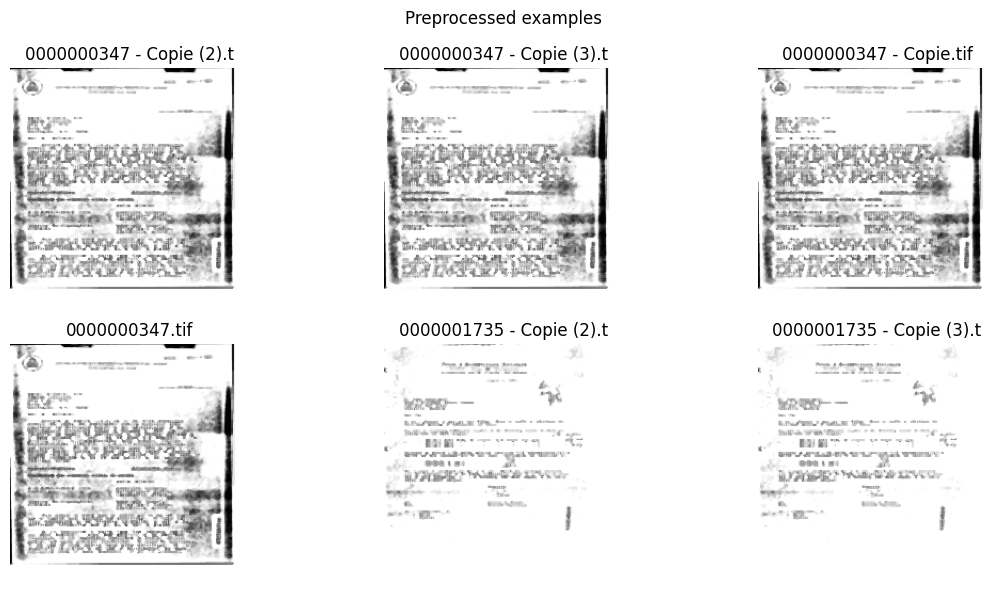

In [7]:

# 7. Visual audit of preprocessing
def show_examples(items, n=6, title="Preprocessed examples"):
    if not items:
        print("No images available.")
        return
    n = min(n, len(items))
    fig, axes = plt.subplots(2, math.ceil(n/2), figsize=(12, 6))
    axes = np.array(axes).reshape(-1)
    for ax, (p, im) in zip(axes, items[:n]):
        ax.imshow(im)
        ax.set_title(Path(p).name[:24])
        ax.axis("off")
    for ax in axes[n:]:
        ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

show_examples(PREP)



## 5. Sixteen-dimensional handcrafted descriptor

The source-aligned descriptor has these 16 fields:

1. ink ratio
2. mean intensity
3. intensity standard deviation
4. edge density
5. log connected-component count
6. largest-component ratio
7. log mean component area
8. row-projection entropy
9. column-projection entropy
10. row-projection peak
11. column-projection peak
12. aspect ratio
13. text-line density
14. whitespace ratio
15. mean saturation
16. saturation standard deviation

The supplied archive execution reported zero variance for aspect ratio and both saturation features after preprocessing. Such constants should be diagnosed rather than interpreted as useful discriminative evidence.


In [8]:

# 8. Exact source-aligned 16-D feature extractor
FEATURE_NAMES = [
    "ink_ratio", "mean_intensity", "std_intensity", "edge_density",
    "n_components_log", "largest_comp_ratio", "mean_comp_area_log",
    "row_proj_entropy", "col_proj_entropy", "row_proj_peak",
    "col_proj_peak", "aspect_ratio", "text_line_density",
    "whitespace_ratio", "color_saturation_mean",
    "color_saturation_std"
]

def handcrafted_features(img_rgb):
    img = img_rgb.astype(np.uint8)
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)
    H, W = gray.shape
    eps = 1e-8

    thr = cv2.threshold(
        gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
    )[1]

    ink_ratio = float((thr > 0).mean())
    mean_int = float(gray.mean()) / 255.0
    std_int = float(gray.std()) / 255.0

    edges = cv2.Canny(gray, 50, 150)
    edge_density = float((edges > 0).mean())

    n_lbl, labels, stats, _ = cv2.connectedComponentsWithStats(thr, connectivity=8)
    areas = stats[1:, cv2.CC_STAT_AREA] if n_lbl > 1 else np.array([0])

    n_comp_log = float(np.log1p(len(areas)))
    largest_ratio = float(areas.max() / (areas.sum() + eps)) if len(areas) else 0.0
    mean_area_log = float(np.log1p(areas.mean())) if len(areas) else 0.0

    row_proj = (thr > 0).sum(axis=1).astype(np.float32)
    col_proj = (thr > 0).sum(axis=0).astype(np.float32)

    def _entropy(p):
        p = p / (p.sum() + eps)
        return float(-(p * np.log(p + eps)).sum())

    row_ent = _entropy(row_proj)
    col_ent = _entropy(col_proj)
    row_peak = float(row_proj.max() / (H + eps))
    col_peak = float(col_proj.max() / (W + eps))

    aspect_ratio = float(W / (H + eps))
    row_mean = row_proj.mean()
    lines = ((row_proj > row_mean) &
             (np.roll(row_proj, 1) <= row_mean)).sum()
    text_line_density = float(lines / (H + eps))
    whitespace_ratio = float((gray > 200).mean())

    sat = hsv[:, :, 1].astype(np.float32) / 255.0
    sat_mean = float(sat.mean())
    sat_std = float(sat.std())

    return np.array([
        ink_ratio, mean_int, std_int, edge_density,
        n_comp_log, largest_ratio, mean_area_log,
        row_ent, col_ent, row_peak, col_peak,
        aspect_ratio, text_line_density, whitespace_ratio,
        sat_mean, sat_std
    ], dtype=np.float32)

if PREP:
    X_hand = np.vstack([handcrafted_features(im) for _, im in PREP])
    PATHS = [str(p) for p, _ in PREP]
    hand_df = pd.DataFrame(X_hand, columns=FEATURE_NAMES)
    print("Handcrafted shape:", X_hand.shape)
    display(hand_df.describe().T[["mean", "std", "min", "max"]])
else:
    X_hand = np.empty((0, 16), dtype=np.float32)
    PATHS = []


Handcrafted shape: (683, 16)


,mean,std,min,max
ink_ratio,0.161566,0.183047,0.001176,0.902324
mean_intensity,0.881742,0.172656,0.105492,0.999577
std_intensity,0.162712,0.115544,0.007912,0.490058
edge_density,0.077890,0.071913,0.000996,0.351343
n_components_log,3.351007,1.195893,0.693147,6.095825
largest_comp_ratio,0.504376,0.279762,0.034870,1.000000
mean_comp_area_log,4.966285,1.448406,2.515480,10.587821
row_proj_entropy,4.568268,0.669685,1.407800,5.394664
col_proj_entropy,4.543646,0.792930,1.274026,5.398777
row_proj_peak,0.508098,0.302175,0.017857,1.000000


,feature,variance,missing,constant
0,ink_ratio,0.033457,0,False
1,mean_intensity,0.029766,0,False
2,std_intensity,0.013331,0,False
3,edge_density,0.005164,0,False
4,n_components_log,1.428067,0,False
5,largest_comp_ratio,0.078152,0,False
6,mean_comp_area_log,2.094810,0,False
7,row_proj_entropy,0.447821,0,False
8,col_proj_entropy,0.627817,0,False
9,row_proj_peak,0.091176,0,False


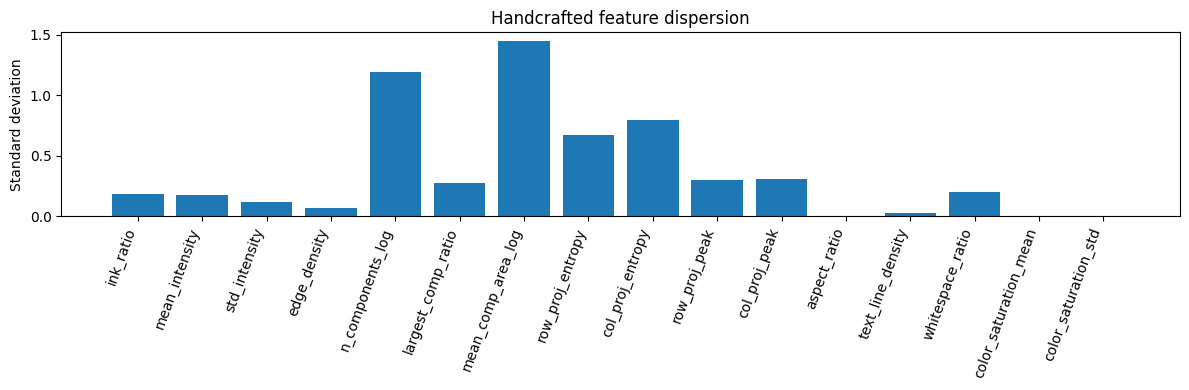

In [9]:

# 9. Feature diagnostics: variance and correlations
if len(X_hand):
    feature_diag = pd.DataFrame({
        "feature": FEATURE_NAMES,
        "variance": X_hand.var(axis=0),
        "missing": np.isnan(X_hand).sum(axis=0),
    })
    feature_diag["constant"] = feature_diag["variance"] < 1e-12
    display(feature_diag)

    plt.figure(figsize=(12, 4))
    plt.bar(FEATURE_NAMES, X_hand.std(axis=0))
    plt.xticks(rotation=70, ha="right")
    plt.ylabel("Standard deviation")
    plt.title("Handcrafted feature dispersion")
    plt.tight_layout()
    plt.show()


In [10]:

# 10. Optional ResNet50 visual features — first 100 of 2048 penultimate dimensions
X_visual = None

if CONFIG["use_resnet50"] and len(PREP):
    try:
        from torchvision.models import resnet50, ResNet50_Weights
        from torchvision import transforms

        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        weights = ResNet50_Weights.IMAGENET1K_V2
        backbone = resnet50(weights=weights)
        backbone.fc = nn.Identity()
        backbone.eval().to(device)

        tfm = transforms.Compose([
            transforms.ToPILImage(),
            transforms.Resize((224, 224)),
            transforms.ToTensor(),
            transforms.Normalize(
                mean=[0.485, 0.456, 0.406],
                std=[0.229, 0.224, 0.225]
            )
        ])

        feats = []
        with torch.no_grad():
            for _, im in PREP:
                x = tfm(im).unsqueeze(0).to(device)
                z = backbone(x).squeeze(0).cpu().numpy()
                feats.append(z[:CONFIG["visual_dims"]])

        X_visual = np.vstack(feats).astype(np.float32)
        print("ResNet50:", X_visual.shape, "device:", device)
    except Exception as e:
        print("ResNet50 unavailable:", repr(e))
        X_visual = None
else:
    print("ResNet50 disabled.")


ResNet50: (683, 100) device: cuda


In [11]:

# 11. Base embedding + standardization + PCA
def build_base_embedding():
    if X_visual is not None:
        return np.hstack([X_hand, X_visual]).astype(np.float32)
    return X_hand.astype(np.float32)

def scale_and_pca(X):
    X = np.nan_to_num(X, nan=0.0, posinf=0.0, neginf=0.0)
    Xs = StandardScaler().fit_transform(X)
    if CONFIG["use_pca"]:
        n_comp = min(CONFIG["pca_target"], Xs.shape[0] - 1, Xs.shape[1])
        Xs = PCA(n_components=n_comp, random_state=SEED_DEFAULT).fit_transform(Xs)
    return Xs.astype(np.float32)

X_base = build_base_embedding()
X_base_proc = scale_and_pca(X_base) if len(X_base) else X_base

print("Base embedding:", X_base.shape)
print("Processed:", X_base_proc.shape)


Base embedding: (683, 116)
Processed: (683, 50)



## 6. Feature-space self-supervised learning

This is the **implemented SSL baseline** described in the supplied validation notebook.

It is deliberately named feature-space SSL rather than raw-image SimCLR:

- input: precomputed document feature vectors;
- two positive views: independent Gaussian perturbations;
- noise standard deviation: 0.12 → 0.02;
- encoder: 512 → 256 → 128;
- projection head: 128-dimensional output;
- NT-Xent temperature: 0.1;
- Adam: `1e-3`, weight decay `1e-5`;
- cosine annealing;
- gradient clipping at 1.0;
- 30 epochs;
- batch size up to 32.

The image-level augmentation helper described by the source materials is **not** silently substituted into this path.


In [12]:

# 12. Feature-space SSL model and NT-Xent
class FeatureSSL(nn.Module):
    def __init__(self, in_dim, hidden=(512, 256, 128),
                 proj_dim=128, dropout=0.1):
        super().__init__()
        layers = []
        d = in_dim
        for h in hidden:
            layers += [
                nn.Linear(d, h),
                nn.BatchNorm1d(h),
                nn.ReLU(inplace=True),
                nn.Dropout(dropout)
            ]
            d = h
        self.encoder = nn.Sequential(*layers)
        self.proj = nn.Sequential(
            nn.Linear(d, d),
            nn.ReLU(inplace=True),
            nn.Linear(d, proj_dim)
        )

    def forward(self, x):
        h = self.encoder(x)
        z = self.proj(h)
        return h, z

def nt_xent(z1, z2, temperature=0.1):
    N = z1.size(0)
    z1 = F.normalize(z1, dim=1)
    z2 = F.normalize(z2, dim=1)
    z = torch.cat([z1, z2], dim=0)
    sim = z @ z.T / temperature
    mask = torch.eye(2 * N, dtype=torch.bool, device=z.device)
    sim = sim.masked_fill(mask, -1e9)
    targets = (torch.arange(2 * N, device=z.device) + N) % (2 * N)
    return F.cross_entropy(sim, targets)

def train_feature_ssl(X, seed=42, epochs=None, verbose=False):
    if not TORCH_AVAILABLE:
        raise RuntimeError("PyTorch is required for SSL.")
    if len(X) < 4:
        return X.copy(), None, []

    seed_everything(seed)
    epochs = epochs or CONFIG["ssl_epochs"]
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    model = FeatureSSL(
        X.shape[1],
        proj_dim=CONFIG["ssl_projection_dim"]
    ).to(device)

    opt = torch.optim.Adam(
        model.parameters(),
        lr=CONFIG["ssl_lr"],
        weight_decay=CONFIG["ssl_weight_decay"]
    )
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)

    Xt = torch.tensor(X, dtype=torch.float32, device=device)
    n = Xt.shape[0]
    bs = max(2, min(CONFIG["ssl_batch_size"], n))
    history = []

    model.train()
    for ep in range(epochs):
        sigma = (
            CONFIG["ssl_sigma_start"] +
            (CONFIG["ssl_sigma_end"] - CONFIG["ssl_sigma_start"])
            * ep / max(1, epochs - 1)
        )

        perm = torch.randperm(n, device=device)
        losses = []

        for start in range(0, n, bs):
            idx = perm[start:start+bs]
            if len(idx) < 2:
                continue
            xb = Xt[idx]
            v1 = xb + sigma * torch.randn_like(xb)
            v2 = xb + sigma * torch.randn_like(xb)

            _, z1 = model(v1)
            _, z2 = model(v2)
            loss = nt_xent(z1, z2, CONFIG["ssl_temperature"])

            opt.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(
                model.parameters(), CONFIG["ssl_grad_clip"]
            )
            opt.step()
            losses.append(loss.item())

        sched.step()
        mean_loss = float(np.mean(losses)) if losses else np.nan
        history.append({"epoch": ep + 1, "sigma": sigma, "loss": mean_loss})

        if verbose and (ep == 0 or (ep + 1) % 5 == 0 or ep == epochs - 1):
            print(f"epoch={ep+1:02d}/{epochs} sigma={sigma:.3f} loss={mean_loss:.5f}")

    model.eval()
    with torch.no_grad():
        H, Z = model(Xt)

    return H.cpu().numpy().astype(np.float32), model, pd.DataFrame(history)

# Example:
# H_ssl, ssl_model, ssl_history = train_feature_ssl(X_base_proc, seed=42, verbose=True)



## 7. Clustering registry and cluster-count selection

Implemented clustering options:

- K-Means
- Mini-Batch K-Means
- Gaussian mixture
- agglomerative clustering
- DBSCAN
- spectral clustering
- affinity propagation
- bootstrap consensus clustering

The source-aligned cluster-count selector evaluates K-Means over `k = 2,...,20`, gives silhouette two votes, and gives Calinski–Harabasz and Davies–Bouldin one vote each.

A separate **stability-aware** criterion `Q(k)` is included as the proposed research extension. It must be evaluated empirically rather than assumed to improve results.


In [13]:

# 13. Clustering registry
from sklearn.neighbors import NearestNeighbors
K_RANGE = list(range(CONFIG["k_min"], CONFIG["k_max"] + 1))

def consensus_clustering(X, k, n_resamples=15, fraction=0.80, seed=42):
    rng = np.random.RandomState(seed)
    n = len(X)
    co = np.zeros((n, n), dtype=np.float32)
    counts = np.zeros((n, n), dtype=np.float32)

    for r in range(n_resamples):
        idx = rng.choice(n, size=max(k, int(fraction*n)), replace=False)
        m = KMeans(n_clusters=k, n_init=5, random_state=seed+r).fit(X[idx])
        lab = m.labels_

        same = (lab[:, None] == lab[None, :]).astype(np.float32)
        co[np.ix_(idx, idx)] += same
        counts[np.ix_(idx, idx)] += 1

    A = np.divide(co, np.maximum(counts, 1),
                  out=np.zeros_like(co), where=counts > 0)
    D = 1.0 - A
    np.fill_diagonal(D, 0.0)

    Z = linkage(squareform(D, checks=False), method="average")
    labels = fcluster(Z, t=k, criterion="maxclust") - 1
    return labels, k, 0.0

def run_clustering(X, algo, k=None, seed=42):
    X = np.asarray(X, dtype=np.float64)

    if algo == "kmeans":
        m = KMeans(n_clusters=k, n_init=10, random_state=seed).fit(X)
        return m.labels_, k, 0.0

    if algo == "minibatch_kmeans":
        m = MiniBatchKMeans(
            n_clusters=k, n_init=10,
            batch_size=min(256, len(X)),
            random_state=seed
        ).fit(X)
        return m.labels_, k, 0.0

    if algo == "gmm":
        m = GaussianMixture(
            n_components=k, covariance_type="full",
            random_state=seed, n_init=3
        ).fit(X)
        return m.predict(X), k, 0.0

    if algo == "agglomerative":
        m = AgglomerativeClustering(n_clusters=k, linkage="ward").fit(X)
        return m.labels_, k, 0.0

    if algo == "spectral":
        m = SpectralClustering(
            n_clusters=k, random_state=seed,
            affinity="nearest_neighbors",
            n_neighbors=min(10, len(X)-1)
        ).fit(X)
        return m.labels_, k, 0.0

    if algo == "dbscan":
        ms = 3
        eps = CONFIG.get("dbscan_eps")
        if not eps:
            kd = NearestNeighbors(n_neighbors=min(ms + 1, len(X))).fit(X).kneighbors(X)[0][:, -1]
            eps = max(float(np.percentile(kd, 90)), 1e-6)
        m = DBSCAN(eps=eps, min_samples=ms).fit(X)
        lab = m.labels_
        noise = float((lab == -1).mean())
        native_k = len(set(lab)) - (1 if -1 in lab else 0)
        return lab, native_k, noise

    if algo == "affinity":
        m = AffinityPropagation(random_state=seed).fit(X)
        lab = m.labels_
        return lab, len(set(lab)), 0.0

    if algo == "consensus":
        return consensus_clustering(
            X, k=k,
            n_resamples=CONFIG["consensus_resamples"],
            fraction=CONFIG["consensus_fraction"],
            seed=seed
        )

    raise ValueError(algo)


In [14]:

# 14. Metrics and cluster-count selection
def internal_metrics(X, labels):
    mask = labels != -1
    if mask.sum() < 3 or len(np.unique(labels[mask])) < 2:
        return np.nan, np.nan, np.nan
    Xm, lm = X[mask], labels[mask]

    try: sil = silhouette_score(Xm, lm)
    except Exception: sil = np.nan
    try: ch = calinski_harabasz_score(Xm, lm)
    except Exception: ch = np.nan
    try: db = davies_bouldin_score(Xm, lm)
    except Exception: db = np.nan
    return sil, ch, db

def select_k_majority_vote(X, k_range=K_RANGE, seed=42):
    rows = []
    for k in k_range:
        if len(X) <= k:
            continue
        lab, _, _ = run_clustering(X, "kmeans", k=k, seed=seed)
        sil, ch, db = internal_metrics(X, lab)
        rows.append({"k": k, "silhouette": sil, "ch": ch, "db": db})

    df = pd.DataFrame(rows)
    if df.empty:
        return None, df

    k_sil = int(df.loc[df["silhouette"].idxmax(), "k"])
    k_ch = int(df.loc[df["ch"].idxmax(), "k"])
    k_db = int(df.loc[df["db"].idxmin(), "k"])
    votes = [k_sil, k_sil, k_ch, k_db]
    k_hat = max(set(votes), key=votes.count)
    return k_hat, df

def select_k_stability_aware(
    X, k_range=K_RANGE, seeds=range(5),
    wS=0.25, wC=0.25, wD=0.25, wA=0.25,
    normalize="across_k"
):
    # normalize="across_k" (default, fixed): silhouette / CH / DB are averaged over seeds and then min-max
    #     normalised ACROSS the candidate k values, so they can actually discriminate between k.
    # normalize="within_seeds" (legacy): min-max across the seeds at each k. This is degenerate: whenever the seeds
    #     agree, S=C=D=1 for every k, Q collapses to the stability term A and the smallest stable k always wins.
    def mm(v, reverse=False):
        v = np.asarray(v, dtype=float)
        if len(v) == 0 or np.allclose(v.max(), v.min()):
            return np.ones_like(v)
        n = (v - v.min()) / (v.max() - v.min())
        return 1 - n if reverse else n

    rows = []
    for k in k_range:
        if len(X) <= k:
            continue
        sils, chs, dbs, labs = [], [], [], []
        for s in seeds:
            lab, _, _ = run_clustering(X, "kmeans", k=k, seed=s)
            s1, c1, d1 = internal_metrics(X, lab)
            sils.append(s1); chs.append(c1); dbs.append(d1); labs.append(lab)
        sils, chs, dbs = np.nan_to_num(sils), np.nan_to_num(chs), np.nan_to_num(dbs)
        pairwise = [adjusted_rand_score(labs[i], labs[j])
                    for i in range(len(labs)) for j in range(i + 1, len(labs))]
        rows.append({
            "k": k, "sil_mean": float(sils.mean()), "ch_mean": float(chs.mean()), "db_mean": float(dbs.mean()),
            "A": float(np.mean(pairwise)) if pairwise else 0.0,
            "S_legacy": mm(sils).mean(), "C_legacy": mm(chs).mean(), "D_legacy": mm(dbs, True).mean(),
        })

    df = pd.DataFrame(rows)
    if df.empty:
        return None, df
    if normalize == "within_seeds":
        df["S"], df["C"], df["D"] = df["S_legacy"], df["C_legacy"], df["D_legacy"]
    else:
        df["S"], df["C"], df["D"] = mm(df["sil_mean"]), mm(df["ch_mean"]), mm(df["db_mean"], True)
    df["Q"] = wS * df["S"] + wC * df["C"] + wD * df["D"] + wA * df["A"]
    df = df.drop(columns=["S_legacy", "C_legacy", "D_legacy"])
    return int(df.loc[df["Q"].idxmax(), "k"]), df

if len(X_base_proc):
    k_majority, k_curve = select_k_majority_vote(X_base_proc, seed=42)
    k_stable, q_curve = select_k_stability_aware(X_base_proc, seeds=[0,1,2,3,4])
    print("Majority-vote k:", k_majority)
    print("Stability-aware Q(k):", k_stable)
    display(k_curve.head())
    display(q_curve.head())


  File "e:\Python\lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
  File "e:\Python\lib\subprocess.py", line 493, in run
    with Popen(*popenargs, **kwargs) as process:
  File "e:\Python\lib\subprocess.py", line 858, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "e:\Python\lib\subprocess.py", line 1311, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,


Majority-vote k: 2
Stability-aware Q(k): 2


,k,silhouette,ch,db
0,2,0.182507,62.230824,2.973217
1,3,0.110371,52.815460,2.652547
2,4,0.082904,45.755152,2.716302
3,5,0.091380,42.540226,2.220014
4,6,0.075291,39.685690,2.281007


,k,sil_mean,ch_mean,db_mean,A,S,C,D,Q
0,2,0.170528,62.235580,2.971283,0.951463,1.000000,1.000000,0.000000,0.737866
1,3,0.106888,52.662125,2.689426,0.847612,0.539443,0.746066,0.241252,0.593593
2,4,0.092811,46.006017,2.582442,0.656043,0.437575,0.569514,0.332823,0.498989
3,5,0.086715,42.579450,2.464332,0.576015,0.393456,0.478626,0.433918,0.470504
4,6,0.073418,39.383952,2.345272,0.720753,0.297226,0.393866,0.535827,0.486918


In [15]:

# 15. External-label metrics: ARI, NMI, purity, Hungarian macro-F1
def evaluate_labels(y_pred, y_true):
    y_pred = np.asarray(y_pred)
    y_true = np.asarray(y_true)

    ari = adjusted_rand_score(y_true, y_pred)
    nmi = normalized_mutual_info_score(y_true, y_pred)

    cm = confusion_matrix(y_true, y_pred)
    purity = cm.max(axis=0).sum() / max(cm.sum(), 1)

    row, col = linear_sum_assignment(-cm)
    mapping = {c: r for r, c in zip(row, col)}
    y_map = np.array([mapping.get(v, -1) for v in y_pred])
    macro_f1 = f1_score(y_true, y_map, average="macro", zero_division=0)

    return {
        "ARI": float(ari),
        "NMI": float(nmi),
        "Purity": float(purity),
        "MacroF1": float(macro_f1)
    }

def pairwise_stability(assignments):
    vals = [
        adjusted_rand_score(assignments[i], assignments[j])
        for i in range(len(assignments))
        for j in range(i+1, len(assignments))
    ]
    return float(np.mean(vals)) if vals else np.nan



## 8. Baseline repeated-seed harness

For a fair representation comparison, the same:

- source manifest,
- preprocessing,
- candidate `k`,
- downstream clustering algorithm,
- seed set,
- and metric definitions

must be used across representations.

The helper below can evaluate fixed features or feature-space SSL. It writes per-run records rather than only aggregate means.


In [16]:

# 16. Matched-seed representation runner
def run_representation(
    X_proc, rep_name,
    algos=("kmeans", "gmm", "consensus"),
    seeds=None,
    use_ssl=False,
    ssl_epochs=None,
    y_true=None
):
    seeds = list(CONFIG["matched_seeds"] if seeds is None else seeds)
    records = []

    for seed in seeds:
        try:
            if use_ssl:
                H, model, hist = train_feature_ssl(
                    X_proc, seed=seed,
                    epochs=ssl_epochs or CONFIG["ssl_epochs"]
                )
                X_use = scale_and_pca(H)
            else:
                X_use = X_proc

            k_hat, _ = select_k_majority_vote(X_use, seed=seed)
            if k_hat is None:
                records.append({
                    "rep": rep_name, "seed": seed,
                    "status": "no_k"
                })
                continue

            for algo in algos:
                lab, native_k, noise = run_clustering(
                    X_use, algo, k=k_hat, seed=seed
                )
                sil, ch, db = internal_metrics(X_use, lab)

                rec = {
                    "rep": rep_name,
                    "seed": seed,
                    "algo": algo,
                    "k_selected": k_hat,
                    "k_native": native_k,
                    "noise_ratio": noise,
                    "silhouette": sil,
                    "ch": ch,
                    "db": db,
                    "status": "ok"
                }

                if y_true is not None:
                    rec.update(evaluate_labels(lab, y_true))

                records.append(rec)

        except Exception as e:
            records.append({
                "rep": rep_name, "seed": seed,
                "status": "failed", "error": repr(e)
            })

    return pd.DataFrame(records)

# Recommended first run:
# baseline_results = run_representation(
#     X_base_proc, "fixed_base",
#     algos=("kmeans", "gmm"),
#     seeds=[0,1,2],
#     use_ssl=False
# )
# display(baseline_results)



## 9. Missing-view stress

The source-aligned archive stress test uses:

- full structural + visual evidence;
- no structural view;
- no visual view;
- random approximately 12% missingness;
- structural-only operation.

These experiments are diagnostics of representation geometry under partial observation. They are **not semantic accuracy measurements**.


In [17]:

# 17. Missing-view construction and stress harness
def apply_missing_view(X_hand, X_visual, mode, seed=0):
    n = len(X_hand)
    avail_s = np.ones(n, dtype=np.float32)
    avail_v = np.ones(n, dtype=np.float32)

    rng = np.random.RandomState(seed)

    if mode == "no_structural":
        avail_s[:] = 0
    elif mode in {"no_visual", "single_view"}:
        avail_v[:] = 0
    elif mode == "random_12pct":
        avail_s[rng.rand(n) < 0.12] = 0
        avail_v[rng.rand(n) < 0.12] = 0
        both = (avail_s == 0) & (avail_v == 0)
        avail_s[both] = 1.0

    Xh = X_hand * avail_s[:, None]
    Xv = (
        X_visual * avail_v[:, None]
        if X_visual is not None
        else np.zeros((n, 0), dtype=np.float32)
    )
    return np.hstack([Xh, Xv]).astype(np.float32), avail_s, avail_v

def run_missing_view_stress(seeds=(0,1,2)):
    if X_visual is None or not len(X_hand):
        print("Requires handcrafted + visual features.")
        return pd.DataFrame()

    rows = []
    modes = ["full", "no_structural", "no_visual",
             "random_12pct", "single_view"]

    for mode in modes:
        for seed in seeds:
            X, av_s, av_v = apply_missing_view(
                X_hand, X_visual, mode, seed=seed
            )
            Xp = scale_and_pca(X)
            k_hat, _ = select_k_majority_vote(Xp, seed=seed)
            lab, _, _ = run_clustering(Xp, "kmeans", k=k_hat, seed=seed)
            sil, ch, db = internal_metrics(Xp, lab)

            rows.append({
                "mode": mode, "seed": seed, "k": k_hat,
                "silhouette": sil, "ch": ch, "db": db,
                "struct_availability": av_s.mean(),
                "visual_availability": av_v.mean()
            })

    return pd.DataFrame(rows)

# mv_results = run_missing_view_stress()
# if len(mv_results):
#     display(mv_results.groupby("mode")[["silhouette","ch","db"]].agg(["mean","std"]))
#     mv_results.to_csv(OUT_DIR / "missing_view_stress.csv", index=False)



## 10. Scan-degradation stress

The source-aligned degradation family contains:

- additive noise;
- Gaussian blur;
- contrast shift;
- JPEG quality 15;
- 4× downsample/upsample.

The reported quantity is ARI between the clean and degraded assignments. This is **assignment consistency**, not correctness against external labels.


In [18]:

# 18. Controlled image degradation
def degrade_image(img, kind, seed=0):
    if kind == "clean":
        return img.copy()

    if kind == "noise":
        rng = np.random.RandomState(seed)
        noise = rng.normal(0, 12, img.shape)
        return np.clip(img.astype(np.float32) + noise, 0, 255).astype(np.uint8)

    if kind == "blur":
        return cv2.GaussianBlur(img, (5, 5), 1.5)

    if kind == "contrast":
        return cv2.convertScaleAbs(img, alpha=0.6, beta=20)

    if kind == "jpeg":
        ok, enc = cv2.imencode(".jpg", img, [cv2.IMWRITE_JPEG_QUALITY, 15])
        if not ok:
            raise RuntimeError("JPEG encoding failed")
        return cv2.imdecode(enc, cv2.IMREAD_COLOR)

    if kind == "downsample4x":
        h, w = img.shape[:2]
        small = cv2.resize(img, (max(1,w//4), max(1,h//4)),
                           interpolation=cv2.INTER_AREA)
        return cv2.resize(small, (w, h), interpolation=cv2.INTER_LINEAR)

    raise ValueError(kind)

def run_degradation_stress():
    if not PREP:
        return pd.DataFrame()

    X_clean = np.vstack([handcrafted_features(im) for _, im in PREP])
    Xp_clean = scale_and_pca(X_clean)
    k_clean, _ = select_k_majority_vote(Xp_clean, seed=0)
    lab_clean, _, _ = run_clustering(Xp_clean, "kmeans", k=k_clean, seed=0)

    rows = []
    for kind in ["noise", "blur", "contrast", "jpeg", "downsample4x"]:
        X_deg = np.vstack([
            handcrafted_features(degrade_image(im, kind))
            for _, im in PREP
        ])
        Xp_deg = scale_and_pca(X_deg)
        lab_deg, _, _ = run_clustering(
            Xp_deg, "kmeans", k=k_clean, seed=0
        )
        rows.append({
            "degradation": kind,
            "k": k_clean,
            "ARI_clean_vs_degraded": adjusted_rand_score(
                lab_clean, lab_deg
            )
        })
    return pd.DataFrame(rows)

# degradation_results = run_degradation_stress()
# display(degradation_results)
# degradation_results.to_csv(OUT_DIR / "degradation_stress.csv", index=False)



# 11. Hard synthetic incomplete multi-view fixture

This fixture is intended to test the **logic of incomplete multi-view fusion** under controlled conditions.

Parameters aligned with the supplied evidence:

- `N = 180`;
- `k = 3`;
- structural dimension = 12;
- visual dimension = 16;
- text dimension = 10;
- informative missingness;
- every sample retains at least one view.

The fixture is useful for implementation testing, but synthetic separability is not evidence of real-archive semantic performance.


In [19]:

# 19. Hard synthetic fixture
def make_hard_fixture(n=180, k=3, d_s=12, d_v=16, d_t=10, seed=0):
    rng = np.random.RandomState(seed)
    y = rng.randint(0, k, size=n)

    means_s = rng.randn(k, d_s) * 0.6
    means_v = rng.randn(k, d_v) * 0.6
    means_t = rng.randn(k, d_t) * 0.6

    Xs = means_s[y] + rng.randn(n, d_s) * 1.0
    Xv = means_v[y] + rng.randn(n, d_v) * 1.0
    Xt = means_t[y] + rng.randn(n, d_t) * 1.0

    a_s = np.ones(n, dtype=np.float32)
    a_v = np.ones(n, dtype=np.float32)
    a_t = np.ones(n, dtype=np.float32)

    a_t[(y == 0) & (rng.rand(n) < 0.70)] = 0
    a_v[(y == 1) & (rng.rand(n) < 0.70)] = 0
    a_s[(y == 2) & (rng.rand(n) < 0.70)] = 0

    for i in range(n):
        if a_s[i] + a_v[i] + a_t[i] == 0:
            a_s[i] = 1.0

    return Xs.astype(np.float32), Xv.astype(np.float32), Xt.astype(np.float32), \
           a_s, a_v, a_t, y

Xs, Xv, Xt, a_s, a_v, a_t, y_hard = make_hard_fixture(
    n=CONFIG["synthetic_n"],
    k=CONFIG["synthetic_k"],
    seed=0
)

print("N:", len(y_hard))
print("Class counts:", np.bincount(y_hard))
print("Availability:", {
    "structural": float(a_s.mean()),
    "visual": float(a_v.mean()),
    "text": float(a_t.mean())
})


N: 180
Class counts: [67 56 57]
Availability: {'structural': 0.7777777910232544, 'visual': 0.8111110925674438, 'text': 0.7222222089767456}


In [20]:

# 20. Simple non-learned controls on the hard fixture
def concat_with_mask(Xs, Xv, Xt, a_s, a_v, a_t):
    return np.hstack([
        Xs * a_s[:, None],
        Xv * a_v[:, None],
        Xt * a_t[:, None]
    ])

def reliability_weighted_concat(Xs, Xv, Xt, a_s, a_v, a_t):
    W = np.stack([a_s, a_v, a_t], axis=1)
    W = W / (W.sum(axis=1, keepdims=True) + 1e-8)
    return np.hstack([
        Xs * W[:, 0:1],
        Xv * W[:, 1:2],
        Xt * W[:, 2:3]
    ])

hard_rows = []
controls = {
    "structural_only": Xs * a_s[:, None],
    "masked_concat": concat_with_mask(Xs, Xv, Xt, a_s, a_v, a_t),
    "availability_weighted_concat": reliability_weighted_concat(
        Xs, Xv, Xt, a_s, a_v, a_t
    )
}

for name, X in controls.items():
    Xp = scale_and_pca(X)
    lab, _, _ = run_clustering(Xp, "kmeans", k=3, seed=0)
    hard_rows.append({"method": name, **evaluate_labels(lab, y_hard)})

hard_control_df = pd.DataFrame(hard_rows)
display(hard_control_df)
hard_control_df.to_csv(OUT_DIR / "hard_fixture_controls.csv", index=False)


,method,ARI,NMI,Purity,MacroF1
0,structural_only,0.480841,0.483049,0.783333,0.780811
1,masked_concat,0.877540,0.831088,0.955556,0.953428
2,availability_weighted_concat,0.877597,0.836414,0.955556,0.953401



# 12. Executable HAMV-CC research extension

The following module implements the proposed mechanisms as an **experimental extension**:

- separate view encoders;
- explicit availability masks;
- view-local reliability scores;
- reliability-gated fusion;
- instance-level contrastive loss;
- cross-view consistency;
- cluster-consistency loss;
- entropy regularization;
- optional prototype-based soft clustering.

This is deliberately separated from the source-aligned baseline. It is the place to run the experiments that the manuscript says are still required before making a superiority claim on the real archive.


In [21]:

# 21. HAMV-CC model
class ViewEncoder(nn.Module):
    def __init__(self, in_dim, latent_dim=128):
        super().__init__()
        hidden = max(64, min(256, 2 * latent_dim))
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden),
            nn.BatchNorm1d(hidden),
            nn.ReLU(),
            nn.Linear(hidden, latent_dim),
            nn.LayerNorm(latent_dim)
        )

    def forward(self, x):
        return self.net(x)

class ReliabilityGate(nn.Module):
    def __init__(self, latent_dim):
        super().__init__()
        self.score = nn.Sequential(
            nn.Linear(latent_dim + 1, max(32, latent_dim // 2)),
            nn.ReLU(),
            nn.Linear(max(32, latent_dim // 2), 1)
        )

    def forward(self, h, reliability, available):
        r = reliability.unsqueeze(1)
        a = available.unsqueeze(1)
        raw = self.score(torch.cat([h, r], dim=1))
        raw = raw.masked_fill(a <= 0, -1e9)
        return raw

class HAMVCC(nn.Module):
    def __init__(self, input_dims, latent_dim=128, proj_dim=128, n_clusters=3):
        super().__init__()
        self.n_views = len(input_dims)
        self.latent_dim = latent_dim

        self.encoders = nn.ModuleList([
            ViewEncoder(d, latent_dim) for d in input_dims
        ])
        self.gates = nn.ModuleList([
            ReliabilityGate(latent_dim) for _ in input_dims
        ])

        self.proj = nn.Sequential(
            nn.Linear(latent_dim, latent_dim),
            nn.ReLU(),
            nn.Linear(latent_dim, proj_dim)
        )

        self.cluster_head = nn.Linear(latent_dim, n_clusters)

    def encode_views(self, views, avail, reliability):
        hs = []
        logits = []

        for m, x in enumerate(views):
            h = self.encoders[m](x)
            g = self.gates[m](h, reliability[m], avail[m])
            hs.append(h)
            logits.append(g)

        logits = torch.cat(logits, dim=1)
        alpha = torch.softmax(logits, dim=1)

        fused = torch.zeros_like(hs[0])
        for m, h in enumerate(hs):
            fused = fused + alpha[:, m:m+1] * h

        fused = F.normalize(fused, dim=1)
        return hs, alpha, fused

    def forward(self, views, avail, reliability):
        hs, alpha, fused = self.encode_views(views, avail, reliability)
        z = F.normalize(self.proj(fused), dim=1)
        q = F.softmax(self.cluster_head(fused), dim=1)
        return {
            "view_embeddings": hs,
            "weights": alpha,
            "fused": fused,
            "projection": z,
            "cluster_probs": q
        }


In [22]:

# 22. HAMV-CC objective components
def symmetric_js(p, q, eps=1e-8):
    p = p.clamp_min(eps)
    q = q.clamp_min(eps)
    m = 0.5 * (p + q)
    return 0.5 * (
        F.kl_div(m.log(), p, reduction="batchmean") +
        F.kl_div(m.log(), q, reduction="batchmean")
    )

def cross_view_consistency(view_embeddings, avail):
    losses = []
    for i in range(len(view_embeddings)):
        for j in range(i+1, len(view_embeddings)):
            both = (avail[i] > 0) & (avail[j] > 0)
            if both.sum() < 2:
                continue
            hi = F.normalize(view_embeddings[i][both], dim=1)
            hj = F.normalize(view_embeddings[j][both], dim=1)
            losses.append(1.0 - (hi * hj).sum(dim=1).mean())
    return torch.stack(losses).mean() if losses else view_embeddings[0].new_tensor(0.0)

def entropy_regularizer(q, eps=1e-8):
    q = q.clamp_min(eps)
    ent = -(q * q.log()).sum(dim=1).mean()
    return -ent

def hamvcc_loss(
    out1, out2,
    avail,
    temperature=0.1,
    lambda_inst=1.0,
    lambda_view=0.5,
    lambda_cc=0.5,
    lambda_reg=0.01
):
    inst = nt_xent(
        out1["projection"],
        out2["projection"],
        temperature=temperature
    )

    view = cross_view_consistency(
        out1["view_embeddings"], avail
    )

    cc = symmetric_js(
        out1["cluster_probs"],
        out2["cluster_probs"]
    )

    reg = entropy_regularizer(out1["cluster_probs"])

    total = (
        lambda_inst * inst +
        lambda_view * view +
        lambda_cc * cc +
        lambda_reg * reg
    )

    return total, {
        "instance": float(inst.detach().cpu()),
        "cross_view": float(view.detach().cpu()),
        "cluster_consistency": float(cc.detach().cpu()),
        "entropy_reg": float(reg.detach().cpu()),
        "total": float(total.detach().cpu())
    }


In [23]:

# 23. Synthetic HAMV-CC training harness
def make_reliability_tensor(Xs, Xv, Xt, a_s, a_v, a_t):
    # Label-free, view-local reliability proxies.
    # Here we use availability as the conservative default.
    return np.stack([a_s, a_v, a_t], axis=0).astype(np.float32)

def hamvcc_train_synthetic(
    Xs, Xv, Xt, a_s, a_v, a_t,
    y=None, seed=42, epochs=100, lr=1e-3,
    latent_dim=64, n_clusters=3, verbose=False
):
    if not TORCH_AVAILABLE:
        raise RuntimeError("PyTorch is required.")

    seed_everything(seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    Xs_t = torch.tensor(Xs, dtype=torch.float32, device=device)
    Xv_t = torch.tensor(Xv, dtype=torch.float32, device=device)
    Xt_t = torch.tensor(Xt, dtype=torch.float32, device=device)

    A = torch.tensor(
        np.stack([a_s, a_v, a_t], axis=0),
        dtype=torch.float32, device=device
    )
    R = A.clone()

    model = HAMVCC(
        [Xs.shape[1], Xv.shape[1], Xt.shape[1]],
        latent_dim=latent_dim,
        proj_dim=latent_dim,
        n_clusters=n_clusters
    ).to(device)

    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)
    history = []

    for ep in range(epochs):
        model.train()

        views1 = [
            Xs_t + 0.05 * torch.randn_like(Xs_t),
            Xv_t + 0.05 * torch.randn_like(Xv_t),
            Xt_t + 0.05 * torch.randn_like(Xt_t),
        ]
        views2 = [
            Xs_t + 0.05 * torch.randn_like(Xs_t),
            Xv_t + 0.05 * torch.randn_like(Xv_t),
            Xt_t + 0.05 * torch.randn_like(Xt_t),
        ]

        out1 = model(views1, A, R)
        out2 = model(views2, A, R)

        loss, parts = hamvcc_loss(
            out1, out2, A,
            temperature=0.1,
            lambda_inst=1.0,
            lambda_view=0.5,
            lambda_cc=0.5,
            lambda_reg=0.01
        )

        opt.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()

        parts["epoch"] = ep + 1
        history.append(parts)

        if verbose and (ep == 0 or (ep+1) % 20 == 0 or ep == epochs-1):
            print(
                f"epoch={ep+1:03d}/{epochs} "
                f"total={parts['total']:.4f} "
                f"inst={parts['instance']:.4f} "
                f"view={parts['cross_view']:.4f} "
                f"cc={parts['cluster_consistency']:.4f}"
            )

    model.eval()
    with torch.no_grad():
        out = model(
            [Xs_t, Xv_t, Xt_t],
            A, R
        )
        labels = out["cluster_probs"].argmax(dim=1).cpu().numpy()
        weights = out["weights"].cpu().numpy()
        fused = out["fused"].cpu().numpy()

    return model, labels, fused, weights, pd.DataFrame(history)

# Example actual execution:
# model, pred, fused, weights, hist = hamvcc_train_synthetic(
#     Xs, Xv, Xt, a_s, a_v, a_t,
#     seed=42, epochs=100, verbose=True
# )
# print(evaluate_labels(pred, y_hard))



## 13. Ten-seed synthetic evaluation

This cell is intentionally executable but not automatically forced to run at notebook opening. It records:

- ARI;
- NMI;
- purity;
- macro-F1;
- pairwise assignment stability;
- learned average view weights.

Use it to generate **new** evidence. Do not replace the manuscript's existing executed values with outputs from a different configuration without documenting the change.


In [24]:

# 24. Ten-seed synthetic HAMV-CC experiment
def run_hamvcc_synthetic_seeds(seeds=range(10), epochs=100):
    all_runs = []
    assignments = []
    weight_rows = []

    for seed in seeds:
        Xs, Xv, Xt, a_s, a_v, a_t, y = make_hard_fixture(
            n=180, k=3, seed=seed
        )

        model, pred, fused, weights, hist = hamvcc_train_synthetic(
            Xs, Xv, Xt, a_s, a_v, a_t,
            seed=seed, epochs=epochs, verbose=False
        )

        metrics = evaluate_labels(pred, y)
        metrics.update({
            "seed": seed,
            "loss_final": float(hist["total"].iloc[-1]),
            "mean_weight_structural": float(weights[:,0].mean()),
            "mean_weight_visual": float(weights[:,1].mean()),
            "mean_weight_text": float(weights[:,2].mean()),
        })

        all_runs.append(metrics)
        assignments.append(pred)

    results = pd.DataFrame(all_runs)
    stability = pairwise_stability(assignments)
    return results, stability

# To execute:
# hamv_runs, hamv_stability = run_hamvcc_synthetic_seeds(range(10), epochs=100)
# display(hamv_runs)
# print("Pairwise seed ARI:", hamv_stability)
# hamv_runs.to_csv(OUT_DIR / "hamvcc_synthetic_10seed.csv", index=False)



# 14. Component ablation matrix

Recommended ablations:

| Condition | Reliability gate | Cross-view consistency | Cluster consistency | Instance contrast |
|---|---:|---:|---:|---:|
| Full | ✓ | ✓ | ✓ | ✓ |
| No reliability | ✗ | ✓ | ✓ | ✓ |
| No cross-view | ✓ | ✗ | ✓ | ✓ |
| No cluster consistency | ✓ | ✓ | ✗ | ✓ |
| No instance contrast | ✓ | ✓ | ✓ | ✗ |

Keep the downstream clustering method and `k` fixed within an ablation. Otherwise an apparent representation effect can be confounded with a different partitioner or cluster-count choice.


In [25]:

# 25. Generic ablation configuration generator
ABLATIONS = {
    "full": {
        "lambda_inst": 1.0,
        "lambda_view": 0.5,
        "lambda_cc": 0.5,
        "use_reliability": True,
    },
    "no_reliability": {
        "lambda_inst": 1.0,
        "lambda_view": 0.5,
        "lambda_cc": 0.5,
        "use_reliability": False,
    },
    "no_cross_view": {
        "lambda_inst": 1.0,
        "lambda_view": 0.0,
        "lambda_cc": 0.5,
        "use_reliability": True,
    },
    "no_cluster_consistency": {
        "lambda_inst": 1.0,
        "lambda_view": 0.5,
        "lambda_cc": 0.0,
        "use_reliability": True,
    },
    "no_instance_contrast": {
        "lambda_inst": 0.0,
        "lambda_view": 0.5,
        "lambda_cc": 0.5,
        "use_reliability": True,
    },
}

pd.DataFrame(ABLATIONS).T


,lambda_inst,lambda_view,lambda_cc,use_reliability
full,1.0,0.5,0.5,True
no_reliability,1.0,0.5,0.5,False
no_cross_view,1.0,0.0,0.5,True
no_cluster_consistency,1.0,0.5,0.0,True
no_instance_contrast,0.0,0.5,0.5,True



# 15. Heuristic document-type descriptions

The source-aligned notebook contains a seven-class heuristic analyzer:

- Form/Table
- Dense Text Document
- Sparse Text Document
- Handwritten Document
- Photo/Image Content
- Mixed Text & Image
- Mostly Blank/Whitespace

Cluster-level majority descriptions should be reported with vote fractions and agreement levels. They are **not independent labels** and should never be used as ground truth for tuning.


In [26]:

# 26. Source-aligned heuristic document-type analyzer
DOC_TYPES = [
    "Form/Table", "Dense Text Document", "Sparse Text Document",
    "Handwritten Document", "Photo/Image Content",
    "Mixed Text & Image", "Mostly Blank/Whitespace"
]

def classify_doc_type(feat):
    (
        ink, mean_i, std_i, edge_d, n_comp, largest_r, mean_a,
        r_ent, c_ent, r_peak, c_peak, aspect, tld, ws, sat_m, sat_s
    ) = feat

    if ws > 0.90 and ink < 0.02:
        return "Mostly Blank/Whitespace"
    if sat_m > 0.35 and ink < 0.10:
        return "Photo/Image Content"
    if ink > 0.35 and edge_d > 0.10 and n_comp > 5:
        return "Dense Text Document"
    if 0.05 < ink < 0.20 and edge_d > 0.05:
        return "Sparse Text Document"
    if largest_r > 0.6 and edge_d < 0.05:
        return "Handwritten Document"
    if r_peak > 0.3 and c_peak > 0.3 and std_i > 0.15:
        return "Form/Table"
    return "Mixed Text & Image"

def describe_clusters(X_proc, labels, feats):
    rows = []
    for c in sorted(set(labels)):
        if c == -1:
            continue
        idx = np.where(labels == c)[0]
        votes = [classify_doc_type(feats[i]) for i in idx]
        maj = max(set(votes), key=votes.count)
        frac = votes.count(maj) / max(len(votes), 1)
        agreement = "High" if frac > 0.80 else ("Medium" if frac >= 0.60 else "Low")
        rows.append({
            "cluster": int(c),
            "size": len(idx),
            "dominant_type": maj,
            "vote_fraction": frac,
            "agreement": agreement
        })
    return pd.DataFrame(rows)

# Example:
# k0, _ = select_k_majority_vote(scale_and_pca(X_hand), seed=0)
# lab0, _, _ = run_clustering(scale_and_pca(X_hand), "kmeans", k=k0, seed=0)
# type_df = describe_clusters(scale_and_pca(X_hand), lab0, X_hand)
# display(type_df)



# 16. Reference evidence ledger

The following table records **previously observed source-aligned results** from the supplied validation notebook. They are included for traceability and comparison, not as freshly generated outputs.

### Previously observed archive stress

| Condition | Silhouette | CH | DB |
|---|---:|---:|---:|
| Full | 0.167595 ± 0.000632 | 62.2391 ± 0.0037 | 2.9711 ± 0.0072 |
| No structural | 0.203416 ± 0.000707 | 43.8653 ± 0.0122 | 3.5698 ± 0.0006 |
| No visual | 0.335222 ± 0.000001 | 391.7010 ± 0.0002 | 1.0455 ± 0.0004 |
| Random 12% | 0.232574 ± 0.004640 | 52.0901 ± 0.8832 | 2.2691 ± 0.4145 |
| Single structural | 0.335222 ± 0.000001 | 391.7010 ± 0.0002 | 1.0455 ± 0.0004 |

### Previously observed clean-vs-degraded assignment ARI

- noise: 0.751521
- blur: 0.864107
- contrast: 0.922756
- JPEG quality 15: 0.907471
- 4× down/up-sampling: 0.849741

These values are diagnostic observations for the specific supplied archive and configuration.



# 17. Previously observed hard-fixture controls

The supplied validation execution reported:

| Method | ARI | NMI | Purity | Macro-F1 |
|---|---:|---:|---:|---:|
| Structural-only | 0.480841 | 0.483049 | 0.783333 | 0.780811 |
| Masked concatenation | 0.877540 | 0.831088 | 0.955556 | 0.953428 |
| Availability-weighted concatenation | 0.877597 | 0.836414 | 0.955556 | 0.953401 |

The important methodological point is that the simple reliability-weighted control nearly matched masked concatenation. Therefore, a future learned reliability gate must be compared against strong non-learned controls rather than against structural-only baselines.


In [27]:

# 27. Plot helpers
def plot_k_curve(k_df, title="Cluster-count diagnostics"):
    if k_df.empty:
        return
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(k_df["k"], k_df["silhouette"], marker="o", label="Silhouette")
    ax.set_xlabel("k")
    ax.set_ylabel("Silhouette")
    ax.set_title(title)
    ax.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

def plot_q_curve(q_df, title="Stability-aware Q(k)"):
    if q_df.empty:
        return
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(q_df["k"], q_df["Q"], marker="o")
    ax.set_xlabel("k")
    ax.set_ylabel("Q(k)")
    ax.set_title(title)
    ax.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

def plot_embedding(X, labels, title, seed=42):
    if len(X) < 5:
        return
    perplexity = min(30, max(2, len(X)-1))
    z = TSNE(
        n_components=2,
        perplexity=perplexity,
        init="pca",
        random_state=seed
    ).fit_transform(X)
    plt.figure(figsize=(7, 5))
    sc = plt.scatter(z[:,0], z[:,1], c=labels, s=12, cmap="tab10")
    plt.title(title)
    plt.xticks([]); plt.yticks([])
    plt.colorbar(sc, label="cluster")
    plt.tight_layout()
    plt.show()

# Example:
# plot_k_curve(k_curve)
# plot_q_curve(q_curve)


In [28]:

# 28. Evidence ledger + environment record
def write_environment_record():
    env = {
        "timestamp": datetime.now().isoformat(),
        "python": sys.version,
        "platform": platform.platform(),
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "opencv": cv2.__version__,
        "torch": getattr(torch, "__version__", None),
        "cuda_available": torch.cuda.is_available() if TORCH_AVAILABLE else False,
        "config": CONFIG,
        "dataset_root": str(DATASET_ROOT) if DATASET_ROOT else None,
        "num_discovered": len(ALL_FILES),
        "num_loaded": len(IMAGES),
        "num_load_failures": len(LOAD_FAILURES),
    }

    with open(OUT_DIR / "run_environment.json", "w", encoding="utf-8") as f:
        json.dump(env, f, indent=2, default=str)

    return env

def index_csv_outputs():
    rows = []
    for csv in sorted(OUT_DIR.glob("*.csv")):
        try:
            df = pd.read_csv(csv)
            rows.append({
                "file": csv.name,
                "rows": len(df),
                "columns": list(df.columns)
            })
        except Exception as e:
            rows.append({
                "file": csv.name,
                "rows": -1,
                "columns": [f"ERROR: {e}"]
            })

    ledger = pd.DataFrame(rows)
    ledger.to_csv(OUT_DIR / "evidence_ledger_index.csv", index=False)
    return ledger

env = write_environment_record()
display(pd.DataFrame([{
    "dataset_root": env["dataset_root"],
    "num_discovered": env["num_discovered"],
    "num_loaded": env["num_loaded"],
    "num_failures": env["num_load_failures"],
    "output_dir": str(OUT_DIR)
}]))
display(index_csv_outputs())


,dataset_root,num_discovered,num_loaded,num_failures,output_dir
0,C:\Users\Debmalya Ray\OneDrive\Desktop\NEW_MOD...,683,683,0,c:\Users\Debmalya Ray\OneDrive\Desktop\NEW_MOD...


,file,rows,columns
0,hard_fixture_controls.csv,3,"[method, ARI, NMI, Purity, MacroF1]"
1,manifest.csv,683,"[path, name, ext, sha256, bytes, error]"



# 18. Final evidence checklist

Before using notebook output in a paper, verify:

### Data
- [ ] source manifest frozen;
- [ ] duplicate policy frozen;
- [ ] all failures retained;
- [ ] preprocessing configuration recorded.

### Representation
- [ ] feature ordering unchanged;
- [ ] visual backbone/version recorded;
- [ ] PCA fit policy frozen;
- [ ] SSL seeds matched.

### HAMV-CC
- [ ] availability masks are explicit;
- [ ] reliability scores are view-local;
- [ ] learned gate is compared with fixed weighting;
- [ ] cross-view and cluster consistency are separately ablated;
- [ ] downstream clusterer is held fixed for ablations.

### Validation
- [ ] internal metrics are labeled as geometric;
- [ ] external semantic labels are independent;
- [ ] repeated seeds are paired;
- [ ] confidence intervals/effect sizes are computed from actual runs;
- [ ] missing-view and degradation conditions are reported;
- [ ] runtime and memory are measured;
- [ ] public benchmark test data remain untouched until freezing.

### Reporting rule
**Do not convert a successful execution of this notebook into a claim of HAMV-CC superiority automatically.** The correct scientific statement depends on the actual matched-seed results, strong controls, independent semantic validation, and external benchmark performance.


In [29]:

# 29. One-command archive of notebook outputs (optional)
# This does not execute experiments; it packages the evidence generated so far.
import shutil

summary = {
    "notebook": "HAMV_CC_InDepth_Reproducible_Research_Notebook.ipynb",
    "output_directory": str(OUT_DIR),
    "generated_at": datetime.now().isoformat(),
    "status": "template + executable research harness",
    "claim_boundary": "New results must be generated from actual execution."
}

with open(OUT_DIR / "RUN_SUMMARY.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)

print(json.dumps(summary, indent=2))
print("Notebook output directory:", OUT_DIR.resolve())


{
  "notebook": "HAMV_CC_InDepth_Reproducible_Research_Notebook.ipynb",
  "output_directory": "c:\\Users\\Debmalya Ray\\OneDrive\\Desktop\\NEW_MODEL\\NEW_FOLDER_03_10_2026\\hamvcc_runs\\20261004_205633",
  "generated_at": "2026-10-04T20:59:06.103893",
  "status": "template + executable research harness",
  "claim_boundary": "New results must be generated from actual execution."
}
Notebook output directory: C:\Users\Debmalya Ray\OneDrive\Desktop\NEW_MODEL\NEW_FOLDER_03_10_2026\hamvcc_runs\20261004_205633


# 19. Publication-quality results and visualization suite

This section adds a presentation and evidence layer without changing the underlying
experimental claims. All figures are generated from executed data when available.
Previously recorded values are labelled as **recorded evidence** and are never silently
recomputed or presented as new experiments.

The visual suite covers dataset/provenance composition, hard-fixture baseline comparison,
ten-seed variability when a run table exists, training-loss decomposition, learned view
weights, component ablations, missing-view robustness, degradation robustness, embedding
geometry, cluster-size balance, and an evidence-status dashboard.

**Important:** internal clustering metrics are geometric diagnostics. ARI/NMI are treated
as semantic metrics only where independent ground-truth labels exist, such as the planted
synthetic fixture.


In [30]:

# 19A. Statistical helpers and publication plotting utilities
import math
from pathlib import Path

def mean_ci95(values):
    x = pd.Series(values, dtype=float).dropna().to_numpy()
    if len(x) == 0:
        return (np.nan, np.nan, np.nan)
    mean = float(x.mean())
    if len(x) == 1:
        return (mean, np.nan, np.nan)
    se = float(x.std(ddof=1) / np.sqrt(len(x)))
    return mean, mean - 1.96 * se, mean + 1.96 * se

def summarize_runs(df, metrics=("ARI","NMI","Purity","MacroF1")):
    if df is None or df.empty:
        return pd.DataFrame()
    rows = []
    for m in metrics:
        if m in df.columns:
            mean, lo, hi = mean_ci95(df[m])
            rows.append({
                "metric": m,
                "mean": mean,
                "std": float(df[m].std(ddof=1)) if len(df) > 1 else np.nan,
                "ci95_low": lo,
                "ci95_high": hi,
                "n": int(df[m].notna().sum())
            })
    return pd.DataFrame(rows)

def savefig(name, dpi=220):
    FIG_DIR = Path(OUT_DIR) / "figures"
    FIG_DIR.mkdir(parents=True, exist_ok=True)
    path = FIG_DIR / name
    plt.savefig(path, dpi=dpi, bbox_inches="tight")
    return path

print("Enhanced plotting/statistics helpers ready.")


Enhanced plotting/statistics helpers ready.


In [31]:

# 19B. Recorded evidence registry
# These values are copied from the existing notebook/manuscript evidence ledger.
# They are NOT rerun here and are not used to fabricate missing experiments.

RECORDED_SYNTHETIC = pd.DataFrame([
    {"method":"HAMV-CC", "ARI":0.8882, "NMI":0.8769, "Purity":np.nan, "MacroF1":np.nan},
    {"method":"Masked reliability-weighted concatenation", "ARI":1.0000, "NMI":1.0000, "Purity":np.nan, "MacroF1":np.nan},
])

RECORDED_HAMV_STABILITY = pd.DataFrame([
    {"measure":"Pairwise seed ARI", "mean":0.8281, "std":0.1037}
])

RECORDED_MISSING_VIEW = pd.DataFrame([
    {"masked_views_pct":0,  "silhouette":0.10760, "CH":114.44, "DB":2.246},
    {"masked_views_pct":10, "silhouette":0.11363, "CH":101.53, "DB":2.547},
    {"masked_views_pct":20, "silhouette":0.10834, "CH":92.71,  "DB":2.659},
    {"masked_views_pct":30, "silhouette":0.09977, "CH":83.61,  "DB":2.829},
    {"masked_views_pct":40, "silhouette":0.09976, "CH":84.05,  "DB":2.741},
])

RECORDED_ARCHIVE_B = pd.DataFrame([
    {"representation":"Handcrafted K-Means", "k":2, "silhouette":0.4130, "CH":85.33, "DB":0.9381},
    {"representation":"Feature-space SSL + K-Means", "k":8, "silhouette":0.1756, "CH":13.99, "DB":1.4043},
])

RECORDED_DEGRADATION = pd.DataFrame([
    {"degradation":"noise", "ARI_clean_vs_degraded":0.8815},
    {"degradation":"JPEG quality 15", "ARI_clean_vs_degraded":0.8815},
    {"degradation":"contrast shift", "ARI_clean_vs_degraded":0.8812},
    {"degradation":"blur", "ARI_clean_vs_degraded":0.7719},
    {"degradation":"4× downsample/upsample", "ARI_clean_vs_degraded":0.5139},
])

display(RECORDED_SYNTHETIC)
display(RECORDED_MISSING_VIEW)
display(RECORDED_ARCHIVE_B)


,method,ARI,NMI,Purity,MacroF1
0,HAMV-CC,0.8882,0.8769,NaN,NaN
1,Masked reliability-weighted concatenation,1.0000,1.0000,NaN,NaN


,masked_views_pct,silhouette,CH,DB
0,0,0.10760,114.44,2.246
1,10,0.11363,101.53,2.547
2,20,0.10834,92.71,2.659
3,30,0.09977,83.61,2.829
4,40,0.09976,84.05,2.741


,representation,k,silhouette,CH,DB
0,Handcrafted K-Means,2,0.4130,85.33,0.9381
1,Feature-space SSL + K-Means,8,0.1756,13.99,1.4043


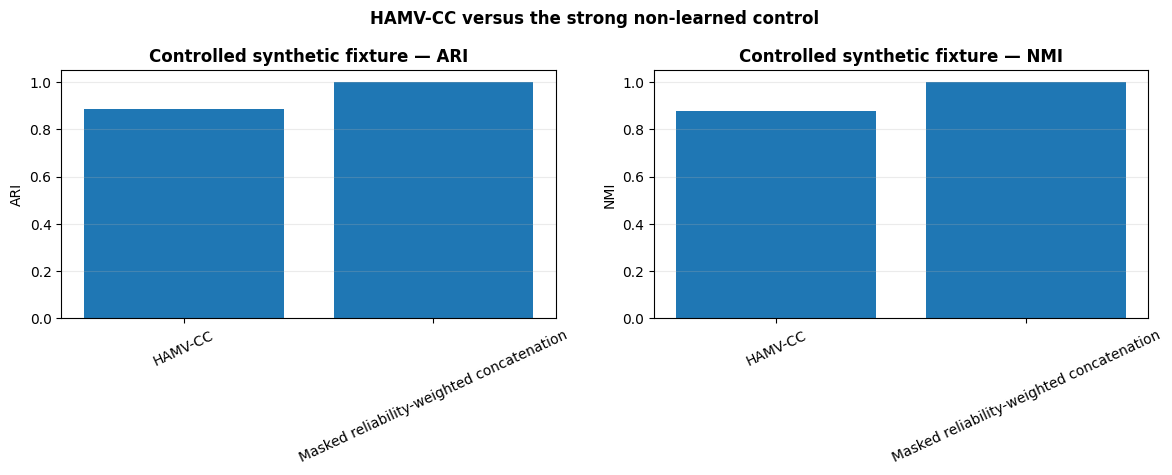

Interpretation: the simpler masked reliability-weighted control reaches 1.0/1.0,
so this fixture validates the pipeline but does not establish HAMV-CC superiority.


In [32]:

# 19C. Synthetic benchmark: method comparison
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

axes[0].bar(RECORDED_SYNTHETIC["method"], RECORDED_SYNTHETIC["ARI"])
axes[0].set_title("Controlled synthetic fixture — ARI", weight="bold")
axes[0].set_ylabel("ARI")
axes[0].tick_params(axis="x", rotation=25)
axes[0].set_ylim(0, 1.05)
axes[0].grid(axis="y", alpha=0.25)

axes[1].bar(RECORDED_SYNTHETIC["method"], RECORDED_SYNTHETIC["NMI"])
axes[1].set_title("Controlled synthetic fixture — NMI", weight="bold")
axes[1].set_ylabel("NMI")
axes[1].tick_params(axis="x", rotation=25)
axes[1].set_ylim(0, 1.05)
axes[1].grid(axis="y", alpha=0.25)

plt.suptitle("HAMV-CC versus the strong non-learned control", weight="bold")
plt.tight_layout()
savefig("fig01_synthetic_method_comparison.png")
plt.show()

print("Interpretation: the simpler masked reliability-weighted control reaches 1.0/1.0,")
print("so this fixture validates the pipeline but does not establish HAMV-CC superiority.")


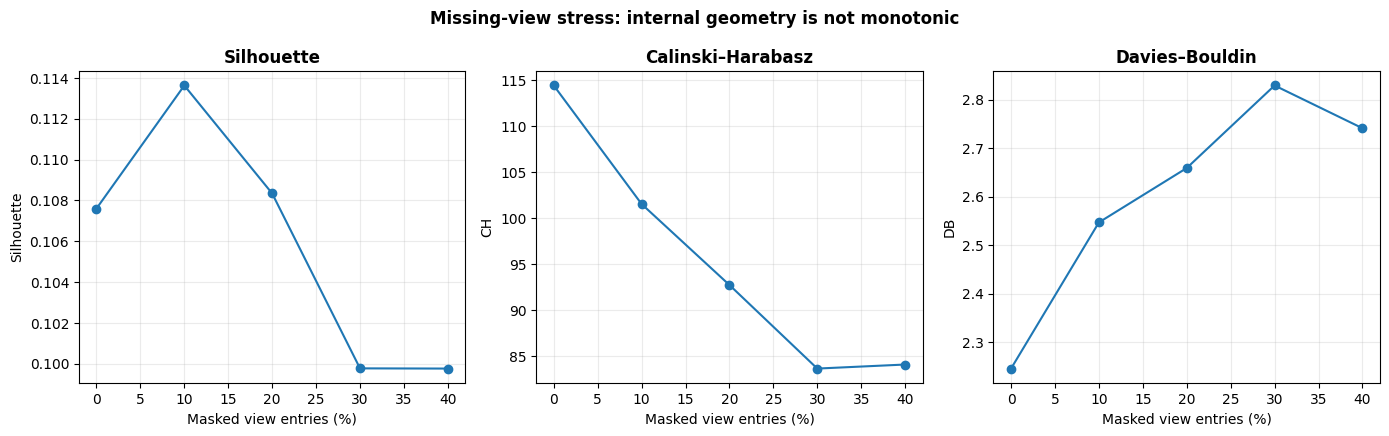

In [33]:

# 19D. Missing-view robustness
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))

axes[0].plot(RECORDED_MISSING_VIEW["masked_views_pct"], RECORDED_MISSING_VIEW["silhouette"], marker="o")
axes[0].set_title("Silhouette", weight="bold")
axes[0].set_xlabel("Masked view entries (%)")
axes[0].set_ylabel("Silhouette")
axes[0].grid(alpha=0.25)

axes[1].plot(RECORDED_MISSING_VIEW["masked_views_pct"], RECORDED_MISSING_VIEW["CH"], marker="o")
axes[1].set_title("Calinski–Harabasz", weight="bold")
axes[1].set_xlabel("Masked view entries (%)")
axes[1].set_ylabel("CH")
axes[1].grid(alpha=0.25)

axes[2].plot(RECORDED_MISSING_VIEW["masked_views_pct"], RECORDED_MISSING_VIEW["DB"], marker="o")
axes[2].set_title("Davies–Bouldin", weight="bold")
axes[2].set_xlabel("Masked view entries (%)")
axes[2].set_ylabel("DB")
axes[2].grid(alpha=0.25)

plt.suptitle("Missing-view stress: internal geometry is not monotonic", weight="bold")
plt.tight_layout()
savefig("fig02_missing_view_stress.png")
plt.show()


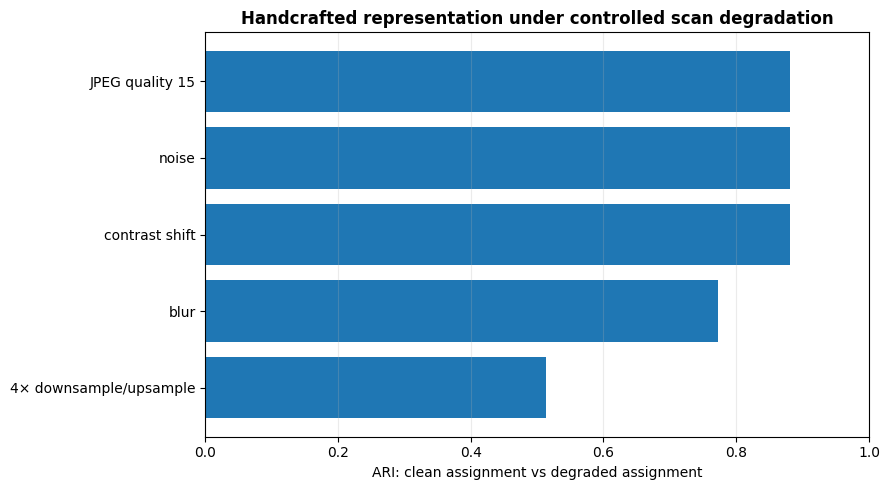

In [34]:

# 19E. Acquisition degradation robustness
fig, ax = plt.subplots(figsize=(9, 5))
tmp = RECORDED_DEGRADATION.sort_values("ARI_clean_vs_degraded", ascending=True)
ax.barh(tmp["degradation"], tmp["ARI_clean_vs_degraded"])
ax.set_xlim(0, 1.0)
ax.set_xlabel("ARI: clean assignment vs degraded assignment")
ax.set_title("Handcrafted representation under controlled scan degradation", weight="bold")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
savefig("fig03_degradation_robustness.png")
plt.show()


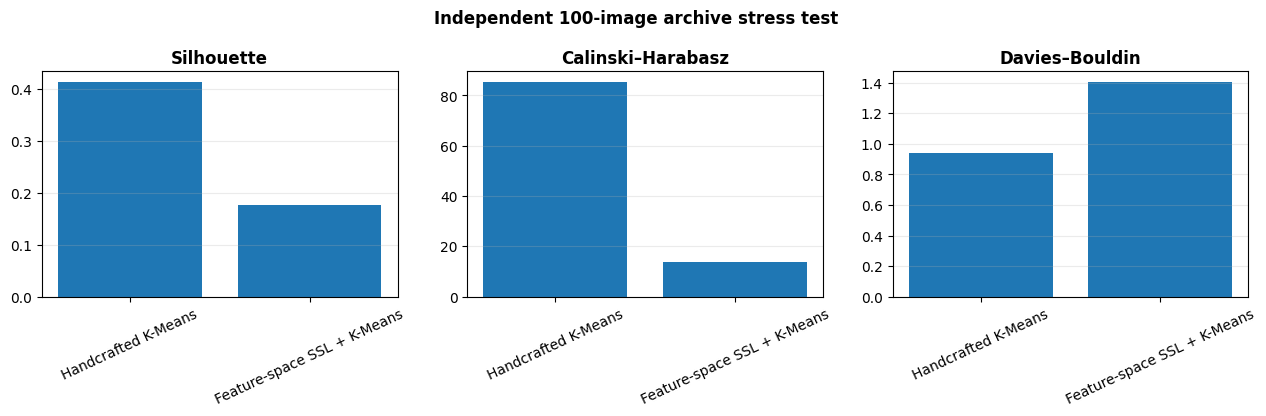

,representation,k,silhouette,CH,DB
0,Handcrafted K-Means,2,0.4130,85.33,0.9381
1,Feature-space SSL + K-Means,8,0.1756,13.99,1.4043


In [35]:

# 19F. Independent archive stress: handcrafted versus feature-space SSL
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
metrics = [("silhouette","Silhouette"), ("CH","Calinski–Harabasz"), ("DB","Davies–Bouldin")]
for ax, (col, label) in zip(axes, metrics):
    ax.bar(RECORDED_ARCHIVE_B["representation"], RECORDED_ARCHIVE_B[col])
    ax.set_title(label, weight="bold")
    ax.tick_params(axis="x", rotation=25)
    ax.grid(axis="y", alpha=0.25)
plt.suptitle("Independent 100-image archive stress test", weight="bold")
plt.tight_layout()
savefig("fig04_archiveB_baseline_comparison.png")
plt.show()

display(RECORDED_ARCHIVE_B)


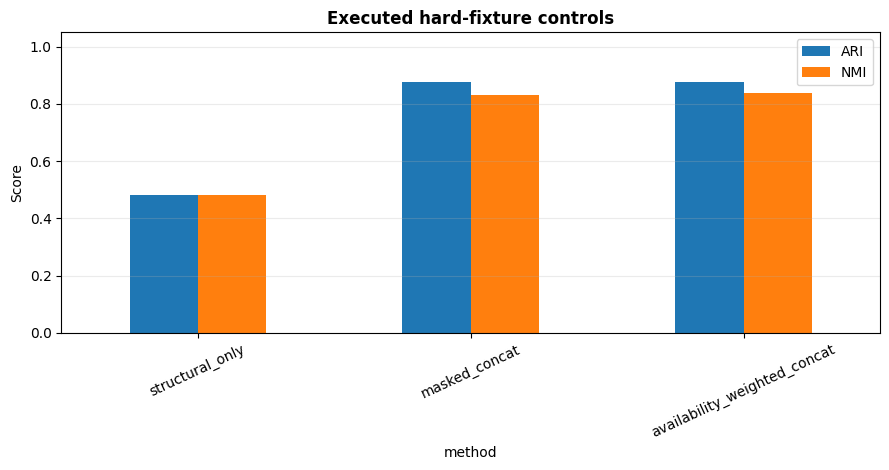

No executed HAMV-CC seed table found; no new performance curve is fabricated.


In [36]:

# 19G. Dynamic visualizations from executed notebook outputs
def load_first_csv(names):
    for name in names:
        p = Path(OUT_DIR) / name
        if p.exists():
            try:
                return pd.read_csv(p), str(p)
            except Exception:
                pass
    return None, None

if "hard_control_df" in globals() and not hard_control_df.empty:
    fig, ax = plt.subplots(figsize=(9, 4.8))
    hard_control_df.set_index("method")[["ARI","NMI"]].plot.bar(ax=ax)
    ax.set_title("Executed hard-fixture controls", weight="bold")
    ax.set_ylabel("Score")
    ax.set_ylim(0, 1.05)
    ax.tick_params(axis="x", rotation=25)
    ax.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    savefig("fig05_executed_hard_controls.png")
    plt.show()

hamv_df = globals().get("hamv_runs", None)
if hamv_df is None:
    hamv_df, src = load_first_csv(["hamvcc_synthetic_10seed.csv"])
else:
    src = "in-memory hamv_runs"

if hamv_df is not None and not hamv_df.empty:
    display(summarize_runs(hamv_df))
    fig, ax = plt.subplots(figsize=(9, 5))
    for metric in ["ARI","NMI","Purity","MacroF1"]:
        if metric in hamv_df.columns:
            ax.plot(hamv_df["seed"], hamv_df[metric], marker="o", label=metric)
    ax.set_xlabel("Seed")
    ax.set_ylabel("Metric")
    ax.set_title(f"HAMV-CC seed sensitivity ({src})", weight="bold")
    ax.legend(frameon=False)
    ax.grid(alpha=0.25)
    plt.tight_layout()
    savefig("fig06_hamvcc_seed_sensitivity.png")
    plt.show()
else:
    print("No executed HAMV-CC seed table found; no new performance curve is fabricated.")

hist_df = globals().get("hist", None)
if hist_df is not None and not hist_df.empty:
    fig, ax = plt.subplots(figsize=(9, 5))
    for col in ["total","instance","cross_view","cluster_consistency","entropy_reg"]:
        if col in hist_df.columns:
            ax.plot(hist_df["epoch"], hist_df[col], label=col)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss component")
    ax.set_title("HAMV-CC training objective decomposition", weight="bold")
    ax.legend(frameon=False)
    ax.grid(alpha=0.25)
    plt.tight_layout()
    savefig("fig07_hamvcc_training_losses.png")
    plt.show()


In [37]:

# 19H. Learned view-weight visualization
weights_obj = globals().get("weights", None)
if weights_obj is not None:
    W = np.asarray(weights_obj)
    if W.ndim == 2 and W.shape[1] >= 3:
        names = ["Structural", "Visual", "Text"]
        fig, ax = plt.subplots(figsize=(8, 5))
        ax.boxplot([W[:,i] for i in range(3)], labels=names, showmeans=True)
        ax.set_ylabel("Fusion weight α")
        ax.set_title("HAMV-CC learned view-weight distribution", weight="bold")
        ax.grid(axis="y", alpha=0.25)
        plt.tight_layout()
        savefig("fig08_view_weight_distribution.png")
        plt.show()
else:
    print("No trained HAMV-CC weight matrix is available in the current session.")


In [38]:

# 19I. Embedding geometry and cluster-size diagnostics
fused_obj = globals().get("fused", None)
pred_obj = globals().get("pred", None)

if fused_obj is not None and pred_obj is not None and len(fused_obj) >= 10:
    plot_embedding(np.asarray(fused_obj), np.asarray(pred_obj),
                   "HAMV-CC fused embedding (executed run)")
    counts = pd.Series(pred_obj).value_counts().sort_index()
    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.bar(counts.index.astype(str), counts.values)
    ax.set_xlabel("Cluster")
    ax.set_ylabel("Documents")
    ax.set_title("HAMV-CC cluster-size balance", weight="bold")
    ax.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    savefig("fig09_cluster_size_balance.png")
    plt.show()
else:
    print("No executed HAMV-CC fused embedding is available for visualization.")


No executed HAMV-CC fused embedding is available for visualization.


In [39]:

# 19J. Reproducibility guard: do not silently promote a non-reproducing run
RECORDED_ARI = 0.8882
RECORDED_NMI = 0.8769

if "pred" in globals() and "y_hard" in globals():
    current = evaluate_labels(pred, y_hard)
    print("Current executed HAMV-CC run:", current)
    print(f"Recorded reference: ARI={RECORDED_ARI:.4f}, NMI={RECORDED_NMI:.4f}")
    if abs(current["ARI"] - RECORDED_ARI) > 0.05 or abs(current["NMI"] - RECORDED_NMI) > 0.05:
        print("\nWARNING: the current executable path does not reproduce the recorded synthetic result.")
        print("Keep both values visible in the evidence ledger and investigate configuration/objective/version differences.")
    else:
        print("Current execution is numerically close to the recorded reference.")
else:
    print("Run the HAMV-CC synthetic experiment before using the reproducibility guard.")


Run the HAMV-CC synthetic experiment before using the reproducibility guard.


# 20. Results interpretation for the paper

The enhanced notebook supports the manuscript's results section with figures that make
the evidence hierarchy visually explicit:

1. **Synthetic validation:** HAMV-CC is executable, but the simpler masked
   reliability-weighted concatenation is a strong control and reaches the planted
   partition perfectly in the recorded fixture.
2. **Missing-view stress:** internal metrics vary non-monotonically; therefore no single
   internal index should be treated as semantic truth.
3. **Acquisition degradation:** resolution loss is a particularly visible failure mode
   in the recorded handcrafted representation.
4. **Independent archive:** feature-space SSL is not automatically beneficial; the
   recorded 100-image execution shows lower geometric separation and lower stability.
5. **Reproducibility guard:** the notebook now checks whether the currently executed
   HAMV-CC implementation actually reproduces the recorded synthetic result.

These visualizations improve the scientific presentation without turning planned
experiments into results. The decisive real-archive HAMV-CC comparison, independent
semantic audit, public benchmark, and efficiency study remain empirical gates.


# 21. End-to-end archive clustering and cluster visualization suite

Sections 6–19 define the clustering registry, the cluster-count selectors, and the HAMV-CC model, but the archive
itself is never clustered end-to-end and there are no cluster-level figures. This section closes that gap.

**What it does (in order)**

| Step | Cell | Output |
|---|---|---|
| Resolve data source (archive, or synthetic fixture if no archive is found) | 21A | views, representations |
| Real-archive multi-view HAMV-CC + feature-space SSL representations | 21B | `REPS` dictionary |
| Compare representations and choose one (auto or manual) | 21C | `clustering_representation_comparison.csv` |
| Cluster-count diagnostics | 21D | k-curve figure |
| Run all eight algorithms at the chosen k | 21E | `clustering_algorithm_results.csv` |
| Final labels, assignments, algorithm agreement | 21F | `clustering_assignments.csv` |
| 2-D embeddings (PCA / t-SNE / optional UMAP) | 21G | embedding figures |
| Silhouette knife, feature profiles, dendrogram, co-association | 21H | structure figures |
| Cluster image montage and borderline documents | 21I | montage figures |
| Bootstrap stability, duplicate-consistency, external-label audit | 21J | stability figures |
| Per-cluster summary, report, optional folder export | 21K | `clustering_summary.csv`, `clustering_report.md` |

**How to use:** run Sections 1–7 and 12 first (through cell 13/14, 21–23 if you want the multi-view model), then run 21A–21K
in order. All choices are in the single `CLUSTER_CFG` dictionary in 21A.

**Evidence boundary (unchanged):** internal metrics (silhouette, Calinski-Harabasz, Davies-Bouldin) are geometric
diagnostics, not semantic ground truth. "Auto" selection of the representation and algorithm is a convenience ranking,
not a scientific claim; for a confirmatory run, freeze `CLUSTER_CFG` before looking at results. ARI/NMI are computed
only when independent labels exist (the synthetic fixture).


In [40]:
# 21A. Clustering suite: configuration and data-source resolution
from IPython.display import display
from sklearn.metrics import silhouette_samples
from sklearn.neighbors import NearestNeighbors

CLUSTER_CFG = {
    # "auto" | "handcrafted" | "base" | "ssl" | "multiview"
    "representation": "auto",
    # "stability" (Q(k) criterion) | "majority" (vote of silhouette/CH/DB) | an integer such as 5
    "k_mode": "stability",
    "algorithms": ["kmeans", "minibatch_kmeans", "gmm", "agglomerative",
                   "spectral", "dbscan", "affinity", "consensus"],
    # None = pick automatically among eligible algorithms; or name one, e.g. "gmm"
    "final_algorithm": None,
    "seed": 42,
    "min_cluster_frac": 0.02,     # eligibility: smallest cluster >= 2% of documents
    "max_noise": 0.30,            # eligibility: DBSCAN-style noise <= 30%
    "max_montage_clusters": 12,
    "n_montage": 8,               # images per cluster row
    "bootstrap_runs": 20,
    "bootstrap_fraction": 0.80,
    "hamvcc_epochs": 150,
    "hamvcc_latent": 64,
    "use_umap": True,             # only used if the umap-learn package is installed
    "export_cluster_folders": False,  # True copies files into clustering_export/cluster_XX/
}

CL_DIR = OUT_DIR                       # CSVs go beside the rest of the evidence ledger
CL_FIG = Path(OUT_DIR) / "figures"
CL_FIG.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.grid": True, "grid.alpha": 0.25,
    "font.size": 10,
})

def clsave(name, dpi=200):
    path = CL_FIG / name
    plt.savefig(path, dpi=dpi, bbox_inches="tight")
    return path

def cluster_palette(labels):
    uniq = [u for u in sorted(set(np.asarray(labels).tolist())) if u != -1]
    cmap = plt.get_cmap("tab10" if len(uniq) <= 10 else "tab20")
    pal = {u: cmap(i % cmap.N) for i, u in enumerate(uniq)}
    pal[-1] = (0.6, 0.6, 0.6, 1.0)
    return pal

def relabel_by_size(lab):
    lab = np.asarray(lab)
    out = np.full_like(lab, -1)
    ids = [u for u in np.unique(lab) if u != -1]
    for new, u in enumerate(sorted(ids, key=lambda u: -(lab == u).sum())):
        out[lab == u] = new
    return out

def cluster_centroids(X, lab):
    return {u: X[lab == u].mean(axis=0) for u in np.unique(lab) if u != -1}

def make_thumb_hog_view(images, size=24, bins=16):
    # Cheap second view that needs no pretrained weights: 24x24 thumbnail + gradient-orientation histogram.
    feats = []
    for im in images:
        g = cv2.cvtColor(im, cv2.COLOR_RGB2GRAY)
        t = cv2.resize(g, (size, size), interpolation=cv2.INTER_AREA).astype(np.float32) / 255.0
        gx = cv2.Sobel(g, cv2.CV_32F, 1, 0)
        gy = cv2.Sobel(g, cv2.CV_32F, 0, 1)
        mag, ang = cv2.cartToPolar(gx, gy)
        h, _ = np.histogram(ang, bins=bins, range=(0, 2 * np.pi), weights=mag)
        h = h / (h.sum() + 1e-8)
        feats.append(np.concatenate([t.ravel(), h]))
    return np.vstack(feats).astype(np.float32)

SEED = CLUSTER_CFG["seed"]
ARCHIVE_MODE = ("PREP" in globals()) and len(PREP) >= 10 and len(X_hand) >= 10
REPS = {}

if ARCHIVE_MODE:
    DATA_MODE = "archive"
    DOC_PATHS = list(PATHS)
    DOC_NAMES = [Path(p).name for p in DOC_PATHS]
    DOC_IMAGES = [im for _, im in IMAGES][:len(DOC_PATHS)]
    Y_TRUE = None
    PROFILE_X, PROFILE_NAMES = X_hand, FEATURE_NAMES
    if X_visual is not None:
        VIEW2, VIEW2_NAME = X_visual, "visual (ResNet50)"
    else:
        VIEW2, VIEW2_NAME = make_thumb_hog_view([im for _, im in PREP]), "visual (thumbnail+HOG)"
    RAW_VIEWS = [("structural", X_hand.astype(np.float32)), (VIEW2_NAME, VIEW2)]
    AVAIL = [np.isfinite(m).all(axis=1).astype(np.float32) for _, m in RAW_VIEWS]
    REPS["handcrafted"] = scale_and_pca(X_hand)
    if X_visual is not None:
        REPS["base"] = X_base_proc            # handcrafted + ResNet50, as in the source pipeline
    else:
        # Without ResNet50 weights X_base_proc would just duplicate 'handcrafted'; use hand + thumbnail/HOG instead.
        REPS["base"] = scale_and_pca(np.hstack([X_hand, VIEW2]))
        print("ResNet50 features unavailable -> 'base' = handcrafted + thumbnail/HOG view.")
else:
    DATA_MODE = "synthetic"
    print("No archive in memory -> running the suite on the hard synthetic fixture so every cell stays executable.")
    if "Xs" not in globals():
        Xs, Xv, Xt, a_s, a_v, a_t, y_hard = make_hard_fixture(n=CONFIG["synthetic_n"], k=CONFIG["synthetic_k"], seed=0)
    DOC_PATHS = [f"synthetic_{i:04d}" for i in range(len(y_hard))]
    DOC_NAMES = DOC_PATHS
    DOC_IMAGES = None
    Y_TRUE = np.asarray(y_hard)
    PROFILE_X = np.hstack([Xs * a_s[:, None], Xv * a_v[:, None], Xt * a_t[:, None]])
    PROFILE_NAMES = ([f"S{i}" for i in range(Xs.shape[1])] + [f"V{i}" for i in range(Xv.shape[1])]
                     + [f"T{i}" for i in range(Xt.shape[1])])
    RAW_VIEWS = [("structural", Xs), ("visual", Xv), ("text", Xt)]
    AVAIL = [a_s, a_v, a_t]
    REPS["handcrafted"] = scale_and_pca(Xs * a_s[:, None])
    REPS["base"] = scale_and_pca(concat_with_mask(Xs, Xv, Xt, a_s, a_v, a_t))

N_DOCS = len(DOC_PATHS)
print(f"Mode: {DATA_MODE} | documents: {N_DOCS}")
for (name, m), a in zip(RAW_VIEWS, AVAIL):
    print(f"  view {name:<24s} dim={m.shape[1]:<4d} availability={a.mean():.3f}")
print("Representations ready so far:", {k: v.shape for k, v in REPS.items()})


Mode: archive | documents: 683
  view structural               dim=16   availability=1.000
  view visual (ResNet50)        dim=100  availability=1.000
Representations ready so far: {'handcrafted': (683, 16), 'base': (683, 50)}


SSL representation: (683, 50)
epoch=001/150 total=7.0530 inst=6.5483 view=1.0233 cc=0.0000
epoch=025/150 total=1.4720 inst=1.2025 view=0.5529 cc=0.0000
epoch=050/150 total=0.5480 inst=0.4815 view=0.1467 cc=0.0000
epoch=075/150 total=0.3917 inst=0.3674 view=0.0624 cc=0.0000
epoch=100/150 total=0.3485 inst=0.3311 view=0.0487 cc=0.0000
epoch=125/150 total=0.3291 inst=0.3153 view=0.0414 cc=0.0000
epoch=150/150 total=0.3135 inst=0.3023 view=0.0363 cc=0.0000
HAMV-CC fused representation: (683, 64)


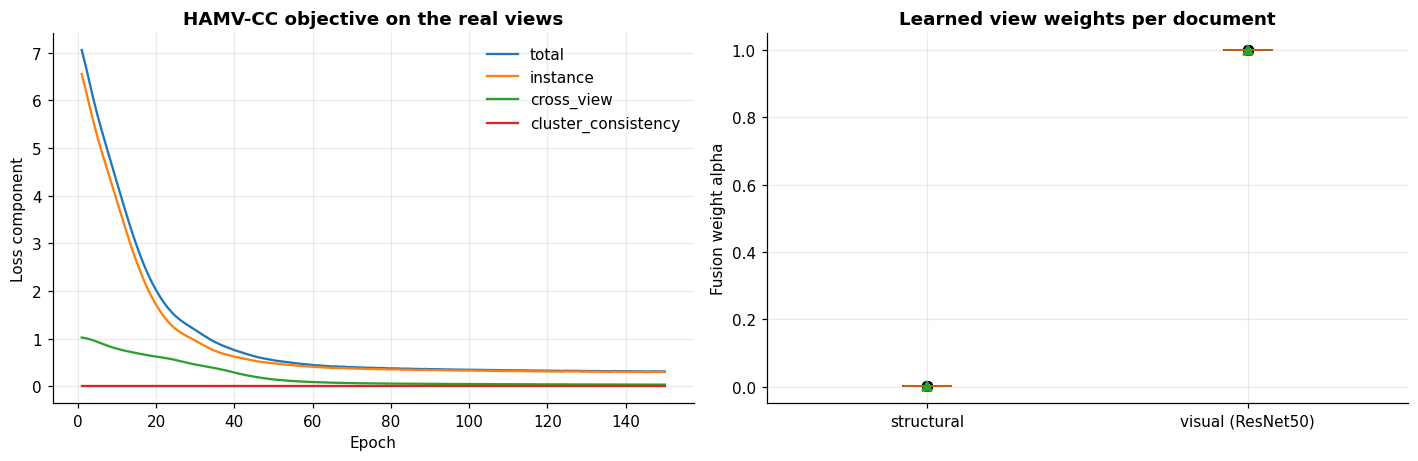

In [41]:
# 21B. Real-data multi-view HAMV-CC trainer and feature-space SSL representation
# The original HAMV-CC harness (cell 23) is hard-wired to the three synthetic views. This version accepts any list of
# views, so the same model, loss and gating can be trained on the real archive.

def view_reliability(X, avail, k=5):
    # Label-free reliability proxy in (0,1): documents that are far from their k nearest neighbours *within this view*
    # (relative to the view's own distribution) are treated as less reliable. Unavailable rows get 0.
    X = np.nan_to_num(X)
    kk = int(min(k + 1, max(2, len(X) - 1)))
    d, _ = NearestNeighbors(n_neighbors=kk).fit(X).kneighbors(X)
    m = d[:, 1:].mean(axis=1)
    z = (m - m.mean()) / (m.std() + 1e-8)
    r = 1.0 / (1.0 + np.exp(z))
    return (r * (avail > 0)).astype(np.float32)

def hamvcc_train_views(views, avail, reliability, n_clusters, seed=42, epochs=150,
                       lr=1e-3, latent_dim=64, noise=0.05, verbose=False):
    if not TORCH_AVAILABLE:
        raise RuntimeError("PyTorch is required for HAMV-CC.")
    seed_everything(seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    V = [torch.tensor(v, dtype=torch.float32, device=device) for v in views]
    A = torch.tensor(np.stack(avail, 0), dtype=torch.float32, device=device)
    R = torch.tensor(np.stack(reliability, 0), dtype=torch.float32, device=device)

    model = HAMVCC([v.shape[1] for v in views], latent_dim=latent_dim,
                   proj_dim=latent_dim, n_clusters=n_clusters).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)
    history = []
    for ep in range(epochs):
        model.train()
        v1 = [x + noise * torch.randn_like(x) for x in V]
        v2 = [x + noise * torch.randn_like(x) for x in V]
        out1, out2 = model(v1, A, R), model(v2, A, R)
        loss, parts = hamvcc_loss(out1, out2, A, temperature=0.1, lambda_inst=1.0,
                                  lambda_view=0.5, lambda_cc=0.5, lambda_reg=0.01)
        opt.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        parts["epoch"] = ep + 1
        history.append(parts)
        if verbose and (ep == 0 or (ep + 1) % 25 == 0 or ep == epochs - 1):
            print(f"epoch={ep+1:03d}/{epochs} total={parts['total']:.4f} inst={parts['instance']:.4f} "
                  f"view={parts['cross_view']:.4f} cc={parts['cluster_consistency']:.4f}")
    model.eval()
    with torch.no_grad():
        out = model(V, A, R)
    return (model, out["cluster_probs"].argmax(1).cpu().numpy(), out["fused"].cpu().numpy(),
            out["weights"].cpu().numpy(), pd.DataFrame(history))

HAMV_REAL = {}
K_GUESS = None
try:
    K_GUESS, _ = select_k_majority_vote(REPS["base"], seed=SEED)
except Exception as e:
    print("k guess failed:", repr(e))
K_GUESS = K_GUESS or 3

if TORCH_AVAILABLE:
    # (a) Feature-space SSL representation (the implemented baseline from cell 12)
    try:
        H_ssl, _, ssl_hist_df = train_feature_ssl(REPS["base"], seed=SEED, verbose=False)
        REPS["ssl"] = scale_and_pca(H_ssl)
        ssl_hist_df.to_csv(CL_DIR / "clustering_ssl_history.csv", index=False)
        print("SSL representation:", REPS["ssl"].shape)
    except Exception as e:
        print("SSL representation skipped:", repr(e))

    # (b) Multi-view HAMV-CC fused embedding on the real views
    try:
        views = [StandardScaler().fit_transform(np.nan_to_num(m)).astype(np.float32) for _, m in RAW_VIEWS]
        rel = [view_reliability(v, a) for v, a in zip(views, AVAIL)]
        model_mv, pred_mv, fused_mv, weights_mv, hist_mv = hamvcc_train_views(
            views, AVAIL, rel, n_clusters=K_GUESS, seed=SEED,
            epochs=CLUSTER_CFG["hamvcc_epochs"], latent_dim=CLUSTER_CFG["hamvcc_latent"], verbose=True)
        REPS["multiview"] = fused_mv.astype(np.float32)
        HAMV_REAL = {"weights": weights_mv, "history": hist_mv, "head_labels": pred_mv,
                     "view_names": [n for n, _ in RAW_VIEWS], "reliability": rel}
        hist_mv.to_csv(CL_DIR / "clustering_hamvcc_history.csv", index=False)
        print("HAMV-CC fused representation:", REPS["multiview"].shape)
    except Exception as e:
        print("HAMV-CC multi-view representation skipped:", repr(e))
else:
    print("PyTorch unavailable: only the 'handcrafted' and 'base' representations will be compared.")

# Training curves and learned view weights (only when the model ran)
if HAMV_REAL:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
    h = HAMV_REAL["history"]
    for col in ["total", "instance", "cross_view", "cluster_consistency"]:
        axes[0].plot(h["epoch"], h[col], label=col)
    axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss component")
    axes[0].set_title("HAMV-CC objective on the real views"); axes[0].legend(frameon=False)
    W = HAMV_REAL["weights"]
    bp = axes[1].boxplot([W[:, i] for i in range(W.shape[1])], labels=HAMV_REAL["view_names"], showmeans=True)
    axes[1].set_ylabel("Fusion weight alpha"); axes[1].set_title("Learned view weights per document")
    plt.tight_layout(); clsave("cl01_hamvcc_training_and_weights.png"); plt.show()


,representation,dim,k_majority,k_stability,k_used,silhouette,CH,DB,seed_stability_ARI,rank_score
0,handcrafted,16,3,3,3,0.3352,391.7013,1.0451,0.9934,1.0000
1,base,50,2,2,2,0.1672,62.2370,2.9670,0.9515,2.0000
2,ssl,50,2,2,2,0.1061,36.5940,4.1143,0.9382,3.3333
3,multiview,64,2,2,2,0.0577,41.0882,4.0062,0.9034,3.6667



Chosen representation: handcrafted | k = 3 | requested = 'auto'
Note: silhouette is not strictly comparable across dimensionalities; override CLUSTER_CFG['representation'] if you have a reason to prefer one.


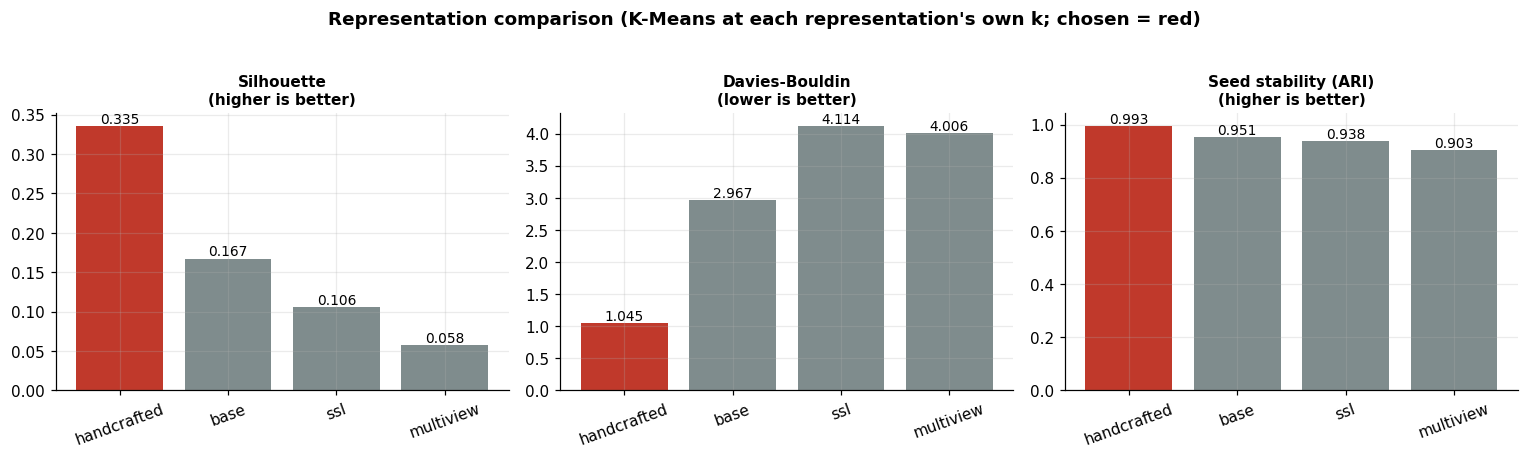

In [42]:
# 21C. Compare representations and choose one
def pick_k(X, mode, seed):
    k_maj, kdf = select_k_majority_vote(X, seed=seed)
    k_stab, qdf = select_k_stability_aware(X, seeds=[0, 1, 2, 3, 4])
    if isinstance(mode, (int, np.integer)):
        k_use = int(mode)
    elif mode == "majority":
        k_use = k_maj
    else:
        k_use = k_stab
    return int(k_use or k_maj or 2), k_maj, k_stab, kdf, qdf

REP_INFO, REP_ROWS = {}, []
for name, X in REPS.items():
    try:
        k_use, k_maj, k_stab, kdf, qdf = pick_k(X, CLUSTER_CFG["k_mode"], SEED)
        labs = [run_clustering(X, "kmeans", k=k_use, seed=s)[0] for s in range(5)]
        sil, ch, db = internal_metrics(X, labs[0])
        row = {"representation": name, "dim": X.shape[1], "k_majority": k_maj, "k_stability": k_stab,
               "k_used": k_use, "silhouette": sil, "CH": ch, "DB": db,
               "seed_stability_ARI": pairwise_stability(labs)}
        if Y_TRUE is not None:
            row.update({f"ext_{k}": v for k, v in evaluate_labels(labs[0], Y_TRUE).items()})
        REP_ROWS.append(row)
        REP_INFO[name] = {"kdf": kdf, "qdf": qdf, "k_use": k_use, "k_maj": k_maj, "k_stab": k_stab}
    except Exception as e:
        print(f"representation {name} failed:", repr(e))

REP_DF = pd.DataFrame(REP_ROWS)
# Convenience ranking (NOT a scientific claim): mean rank of silhouette (high), DB (low), seed stability (high)
REP_DF["rank_score"] = (REP_DF["silhouette"].rank(ascending=False) + REP_DF["DB"].rank(ascending=True)
                        + REP_DF["seed_stability_ARI"].rank(ascending=False)) / 3
REP_DF = REP_DF.sort_values("rank_score").reset_index(drop=True)
REP_DF.to_csv(CL_DIR / "clustering_representation_comparison.csv", index=False)
display(REP_DF.round(4))

req = CLUSTER_CFG["representation"]
CHOSEN_REP = REP_DF.loc[0, "representation"] if req == "auto" else req
if CHOSEN_REP not in REPS:
    print(f"Requested representation '{req}' is unavailable -> falling back to the top-ranked one.")
    CHOSEN_REP = REP_DF.loc[0, "representation"]
X_CL = REPS[CHOSEN_REP]
K_FINAL = REP_INFO[CHOSEN_REP]["k_use"]
print(f"\nChosen representation: {CHOSEN_REP} | k = {K_FINAL} | requested = {req!r}")
print("Note: silhouette is not strictly comparable across dimensionalities; override CLUSTER_CFG['representation'] "
      "if you have a reason to prefer one.")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col, title, better in zip(axes, ["silhouette", "DB", "seed_stability_ARI"],
                                  ["Silhouette", "Davies-Bouldin", "Seed stability (ARI)"],
                                  ["higher is better", "lower is better", "higher is better"]):
    colors = ["#c0392b" if r == CHOSEN_REP else "#7f8c8d" for r in REP_DF["representation"]]
    bars = ax.bar(REP_DF["representation"], REP_DF[col], color=colors)
    for b, v in zip(bars, REP_DF[col]):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{v:.3f}", ha="center", va="bottom", fontsize=9)
    ax.set_title(f"{title}\n({better})", fontsize=10)
    ax.tick_params(axis="x", rotation=20)
fig.suptitle("Representation comparison (K-Means at each representation's own k; chosen = red)", y=1.03, fontweight="bold")
plt.tight_layout(); clsave("cl02_representation_comparison.png"); plt.show()


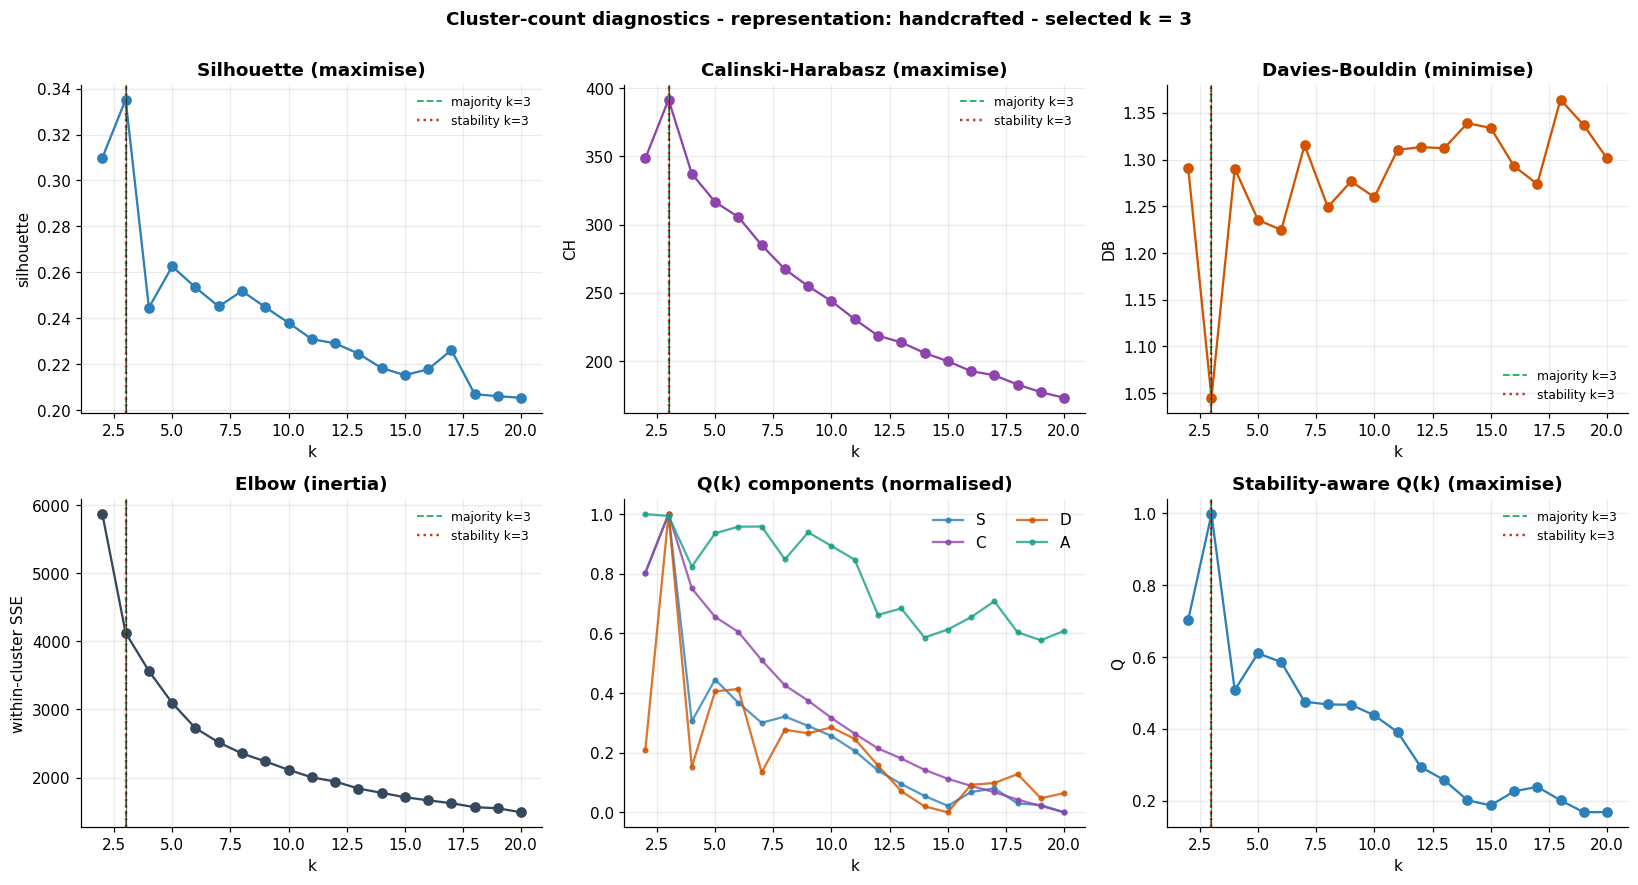

In [43]:
# 21D. Cluster-count diagnostics for the chosen representation
kdf, qdf = REP_INFO[CHOSEN_REP]["kdf"], REP_INFO[CHOSEN_REP]["qdf"]
k_maj, k_stab = REP_INFO[CHOSEN_REP]["k_maj"], REP_INFO[CHOSEN_REP]["k_stab"]

inertia = []
for k in kdf["k"]:
    inertia.append(KMeans(n_clusters=int(k), n_init=5, random_state=SEED).fit(X_CL).inertia_)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
def kplot(ax, x, y, title, ylabel, best=None, color="#2c7fb8"):
    ax.plot(x, y, marker="o", color=color)
    if k_maj is not None:
        ax.axvline(k_maj, color="#27ae60", ls="--", lw=1.2, label=f"majority k={k_maj}")
    if k_stab is not None:
        ax.axvline(k_stab, color="#c0392b", ls=":", lw=1.6, label=f"stability k={k_stab}")
    ax.axvline(K_FINAL, color="k", lw=0.8, alpha=0.5)
    ax.set_title(title); ax.set_xlabel("k"); ax.set_ylabel(ylabel)
    ax.legend(frameon=False, fontsize=8)
kplot(axes[0, 0], kdf["k"], kdf["silhouette"], "Silhouette (maximise)", "silhouette")
kplot(axes[0, 1], kdf["k"], kdf["ch"], "Calinski-Harabasz (maximise)", "CH", color="#8e44ad")
kplot(axes[0, 2], kdf["k"], kdf["db"], "Davies-Bouldin (minimise)", "DB", color="#d35400")
kplot(axes[1, 0], kdf["k"], inertia, "Elbow (inertia)", "within-cluster SSE", color="#34495e")
for col, c in zip(["S", "C", "D", "A"], ["#2c7fb8", "#8e44ad", "#d35400", "#16a085"]):
    axes[1, 1].plot(qdf["k"], qdf[col], marker=".", label=col, color=c, alpha=0.8)
axes[1, 1].set_title("Q(k) components (normalised)"); axes[1, 1].set_xlabel("k"); axes[1, 1].legend(frameon=False, ncol=2)
kplot(axes[1, 2], qdf["k"], qdf["Q"], "Stability-aware Q(k) (maximise)", "Q")
fig.suptitle(f"Cluster-count diagnostics - representation: {CHOSEN_REP} - selected k = {K_FINAL}",
             fontweight="bold", y=1.0)
plt.tight_layout(); clsave("cl03_k_diagnostics.png"); plt.show()
kdf.merge(qdf, on="k", how="outer").to_csv(CL_DIR / "clustering_k_diagnostics.csv", index=False)


,algorithm,seconds,seed_stability_ARI,n_clusters,noise_ratio,min_size,max_size,silhouette,CH,DB,eligible
0,kmeans,0.31,0.9891,3,0.0000,57,320,0.3352,391.7013,1.0451,True
1,minibatch_kmeans,0.80,0.8602,3,0.0000,53,343,0.3360,390.4189,1.0293,True
2,gmm,0.41,1.0000,3,0.0000,56,326,0.3051,351.4028,1.1188,True
3,agglomerative,0.03,1.0000,3,0.0000,56,366,0.3076,351.1730,1.0973,True
4,spectral,0.53,0.9963,3,0.0000,47,324,0.3292,374.8675,1.0315,True
5,dbscan,0.21,1.0000,3,0.0381,3,650,0.0347,6.5903,0.9612,False
6,affinity,0.24,1.0000,34,0.0000,3,41,0.1947,132.6400,1.3281,False
7,consensus,3.26,0.9927,3,0.0000,57,317,0.3352,391.7009,1.0457,True



Final algorithm: minibatch_kmeans  (eligible = >=2 clusters, noise <= 30%, smallest cluster >= 2%)


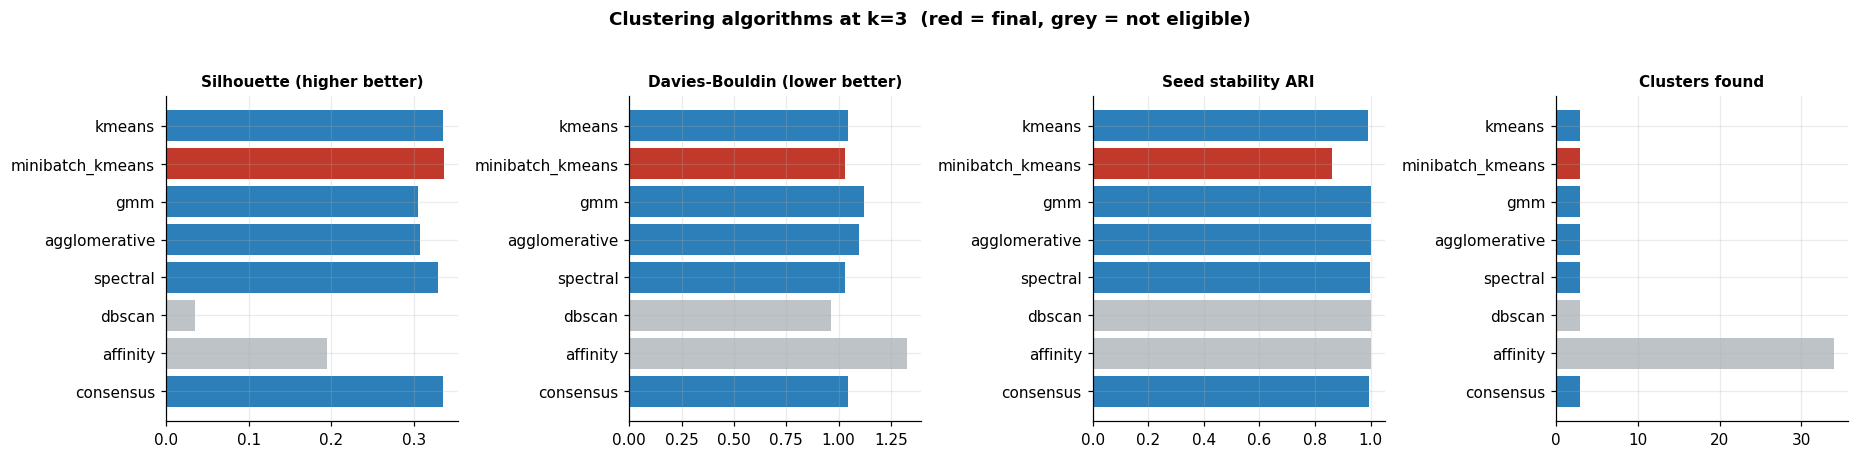

In [44]:
# 21E. Run all eight clustering algorithms on the chosen representation at the chosen k
def summarize_labels(X, lab):
    lab = np.asarray(lab)
    ids = [u for u in np.unique(lab) if u != -1]
    sizes = [int((lab == u).sum()) for u in ids]
    sil, ch, db = internal_metrics(X, lab)
    return {"n_clusters": len(ids), "noise_ratio": float((lab == -1).mean()),
            "min_size": min(sizes) if sizes else 0, "max_size": max(sizes) if sizes else 0,
            "silhouette": sil, "CH": ch, "DB": db}

LABELS, ALGO_ROWS = {}, []
for algo in CLUSTER_CFG["algorithms"]:
    t0 = time.time()
    try:
        lab, native_k, noise = run_clustering(X_CL, algo, k=K_FINAL, seed=SEED)
        elapsed = time.time() - t0
        runs = [np.asarray(lab)] + [np.asarray(run_clustering(X_CL, algo, k=K_FINAL, seed=s)[0])
                                    for s in (SEED + 1, SEED + 2)]
        lab = relabel_by_size(lab)
        LABELS[algo] = lab
        row = {"algorithm": algo, "seconds": round(elapsed, 2), "seed_stability_ARI": pairwise_stability(runs)}
        row.update(summarize_labels(X_CL, lab))
        if Y_TRUE is not None:
            row.update({f"ext_{k}": v for k, v in evaluate_labels(lab, Y_TRUE).items()})
        ALGO_ROWS.append(row)
    except Exception as e:
        print(f"{algo} failed: {e!r}")
        ALGO_ROWS.append({"algorithm": algo, "error": repr(e)})

ALGO_DF = pd.DataFrame(ALGO_ROWS)
ok = ALGO_DF.dropna(subset=["silhouette"]).copy() if "silhouette" in ALGO_DF else pd.DataFrame()
ok["eligible"] = ((ok["n_clusters"] >= 2) & (ok["noise_ratio"] <= CLUSTER_CFG["max_noise"])
                  & (ok["min_size"] >= CLUSTER_CFG["min_cluster_frac"] * N_DOCS))
pool = ok[ok["eligible"]] if ok["eligible"].any() else ok
pool = pool.assign(rank_score=(pool["silhouette"].rank(ascending=False) + pool["DB"].rank(ascending=True)
                               + pool["seed_stability_ARI"].rank(ascending=False)) / 3)
if CLUSTER_CFG["final_algorithm"] in LABELS:
    FINAL_ALGO = CLUSTER_CFG["final_algorithm"]
else:
    FINAL_ALGO = pool.sort_values("rank_score").iloc[0]["algorithm"]
ALGO_DF = ALGO_DF.merge(ok[["algorithm", "eligible"]], on="algorithm", how="left")
ALGO_DF.to_csv(CL_DIR / "clustering_algorithm_results.csv", index=False)
display(ALGO_DF.round(4))
print(f"\nFinal algorithm: {FINAL_ALGO}  (eligible = >=2 clusters, noise <= {CLUSTER_CFG['max_noise']:.0%}, "
      f"smallest cluster >= {CLUSTER_CFG['min_cluster_frac']:.0%})")

fig, axes = plt.subplots(1, 4, figsize=(17, 4))
spec = [("silhouette", "Silhouette (higher better)"), ("DB", "Davies-Bouldin (lower better)"),
        ("seed_stability_ARI", "Seed stability ARI"), ("n_clusters", "Clusters found")]
for ax, (col, title) in zip(axes, spec):
    d = ALGO_DF.dropna(subset=[col])
    colors = ["#c0392b" if a == FINAL_ALGO else ("#bdc3c7" if not e else "#2c7fb8")
              for a, e in zip(d["algorithm"], d["eligible"].fillna(False))]
    ax.barh(d["algorithm"], d[col], color=colors); ax.invert_yaxis()
    ax.set_title(title, fontsize=10)
fig.suptitle("Clustering algorithms at k=%d  (red = final, grey = not eligible)" % K_FINAL, fontweight="bold", y=1.03)
plt.tight_layout(); clsave("cl04_algorithm_comparison.png"); plt.show()


Saved: c:\Users\Debmalya Ray\OneDrive\Desktop\NEW_MODEL\NEW_FOLDER_03_10_2026\hamvcc_runs\20261004_205633\clustering_assignments.csv


,doc_index,name,path,cluster,final_algorithm,representation,silhouette,centroid_margin,dist_to_centroid,sha256,label_kmeans,label_minibatch_kmeans,label_gmm,label_agglomerative,label_spectral,label_dbscan,label_affinity,label_consensus
0,0,0000000347 - Copie (2).tif,C:\Users\Debmalya Ray\OneDrive\Desktop\NEW_MOD...,1,minibatch_kmeans,handcrafted,0.512971,0.705330,1.491200,ac9b0b78ef5f5ee49f37cf89ee2c0143d9faf236c94a82...,1,1,0,0,0,0,3,1
1,1,0000000347 - Copie (3).tif,C:\Users\Debmalya Ray\OneDrive\Desktop\NEW_MOD...,1,minibatch_kmeans,handcrafted,0.512971,0.705331,1.491198,ac9b0b78ef5f5ee49f37cf89ee2c0143d9faf236c94a82...,1,1,0,0,0,0,3,1
2,2,0000000347 - Copie.tif,C:\Users\Debmalya Ray\OneDrive\Desktop\NEW_MOD...,1,minibatch_kmeans,handcrafted,0.512971,0.705330,1.491203,ac9b0b78ef5f5ee49f37cf89ee2c0143d9faf236c94a82...,1,1,0,0,0,0,3,1
3,3,0000000347.tif,C:\Users\Debmalya Ray\OneDrive\Desktop\NEW_MOD...,1,minibatch_kmeans,handcrafted,0.512971,0.705331,1.491199,ac9b0b78ef5f5ee49f37cf89ee2c0143d9faf236c94a82...,1,1,0,0,0,0,3,1
4,4,0000001735 - Copie (2).tif,C:\Users\Debmalya Ray\OneDrive\Desktop\NEW_MOD...,1,minibatch_kmeans,handcrafted,0.111575,0.130993,2.948950,47073ff512345f0795e3d935ea2e0eee52fcf83dd32f98...,1,1,0,0,0,0,14,1
5,5,0000001735 - Copie (3).tif,C:\Users\Debmalya Ray\OneDrive\Desktop\NEW_MOD...,1,minibatch_kmeans,handcrafted,0.111575,0.130993,2.948951,47073ff512345f0795e3d935ea2e0eee52fcf83dd32f98...,1,1,0,0,0,0,14,1
6,6,0000001735 - Copie.tif,C:\Users\Debmalya Ray\OneDrive\Desktop\NEW_MOD...,1,minibatch_kmeans,handcrafted,0.111574,0.130993,2.948952,47073ff512345f0795e3d935ea2e0eee52fcf83dd32f98...,1,1,0,0,0,0,14,1
7,7,0000001735.tif,C:\Users\Debmalya Ray\OneDrive\Desktop\NEW_MOD...,1,minibatch_kmeans,handcrafted,0.111574,0.130993,2.948951,47073ff512345f0795e3d935ea2e0eee52fcf83dd32f98...,1,1,0,0,0,0,14,1


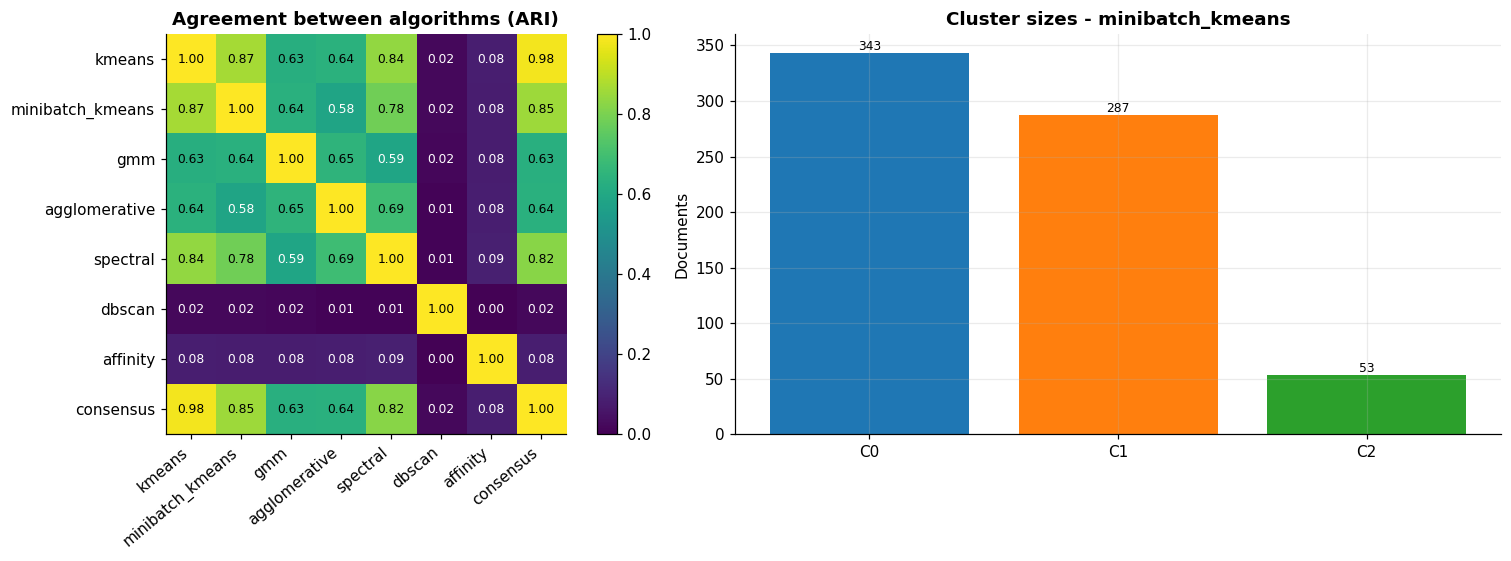

In [45]:
# 21F. Final labels, per-document confidence, assignments table, algorithm agreement
from scipy.spatial.distance import cdist

FINAL_LABELS = LABELS[FINAL_ALGO]
ids_final = [u for u in np.unique(FINAL_LABELS) if u != -1]

sil_s = np.full(N_DOCS, np.nan)
mask = FINAL_LABELS != -1
if len(ids_final) >= 2:
    sil_s[mask] = silhouette_samples(X_CL[mask], FINAL_LABELS[mask])
cent = cluster_centroids(X_CL, FINAL_LABELS)
Dc = cdist(X_CL, np.vstack([cent[i] for i in ids_final])) if ids_final else np.zeros((N_DOCS, 1))
Ds = np.sort(Dc, axis=1)
margin = (Ds[:, 1] - Ds[:, 0]) / (Ds[:, 1] + 1e-8) if Dc.shape[1] >= 2 else np.full(N_DOCS, np.nan)
dist_to_centroid = np.array([Dc[i, ids_final.index(l)] if l != -1 else np.nan for i, l in enumerate(FINAL_LABELS)])

ASSIGN = pd.DataFrame({"doc_index": np.arange(N_DOCS), "name": DOC_NAMES, "path": DOC_PATHS,
                       "cluster": FINAL_LABELS, "final_algorithm": FINAL_ALGO, "representation": CHOSEN_REP,
                       "silhouette": sil_s, "centroid_margin": margin, "dist_to_centroid": dist_to_centroid})
if "MANIFEST" in globals() and ARCHIVE_MODE and not MANIFEST.empty:
    ASSIGN["sha256"] = ASSIGN["path"].map(dict(zip(MANIFEST["path"], MANIFEST["sha256"]))).fillna("")
else:
    ASSIGN["sha256"] = ""
if Y_TRUE is not None:
    ASSIGN["true_label"] = Y_TRUE
for a, l in LABELS.items():
    ASSIGN[f"label_{a}"] = l
ASSIGN.to_csv(CL_DIR / "clustering_assignments.csv", index=False)
print("Saved:", CL_DIR / "clustering_assignments.csv")
display(ASSIGN.head(8))

# --- Algorithm agreement (ARI) and size profiles
names = list(LABELS)
M = np.array([[adjusted_rand_score(LABELS[a], LABELS[b]) for b in names] for a in names])
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw={"width_ratios": [1, 1.25]})
im = axes[0].imshow(M, vmin=0, vmax=1, cmap="viridis")
axes[0].set_xticks(range(len(names))); axes[0].set_yticks(range(len(names)))
axes[0].set_xticklabels(names, rotation=40, ha="right"); axes[0].set_yticklabels(names)
for i in range(len(names)):
    for j in range(len(names)):
        axes[0].text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=8,
                     color="white" if M[i, j] < 0.6 else "black")
axes[0].grid(False); axes[0].set_title("Agreement between algorithms (ARI)")
plt.colorbar(im, ax=axes[0], fraction=0.046)

pal = cluster_palette(FINAL_LABELS)
sizes = pd.Series(FINAL_LABELS).value_counts().sort_index()
axes[1].bar([("noise" if i == -1 else f"C{i}") for i in sizes.index], sizes.values,
            color=[pal[i] for i in sizes.index])
for x, v in enumerate(sizes.values):
    axes[1].text(x, v, str(v), ha="center", va="bottom", fontsize=8)
axes[1].set_title(f"Cluster sizes - {FINAL_ALGO}"); axes[1].set_ylabel("Documents")
plt.tight_layout(); clsave("cl05_agreement_and_sizes.png"); plt.show()


UMAP not used (pip install umap-learn to enable): ModuleNotFoundError


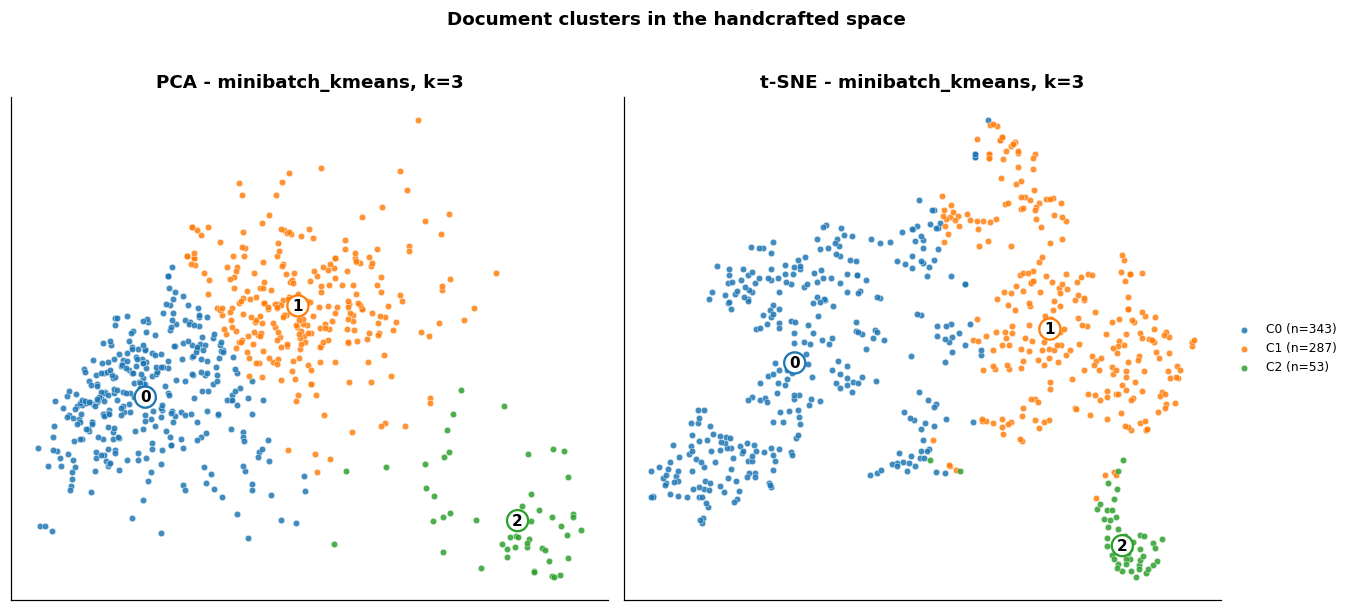

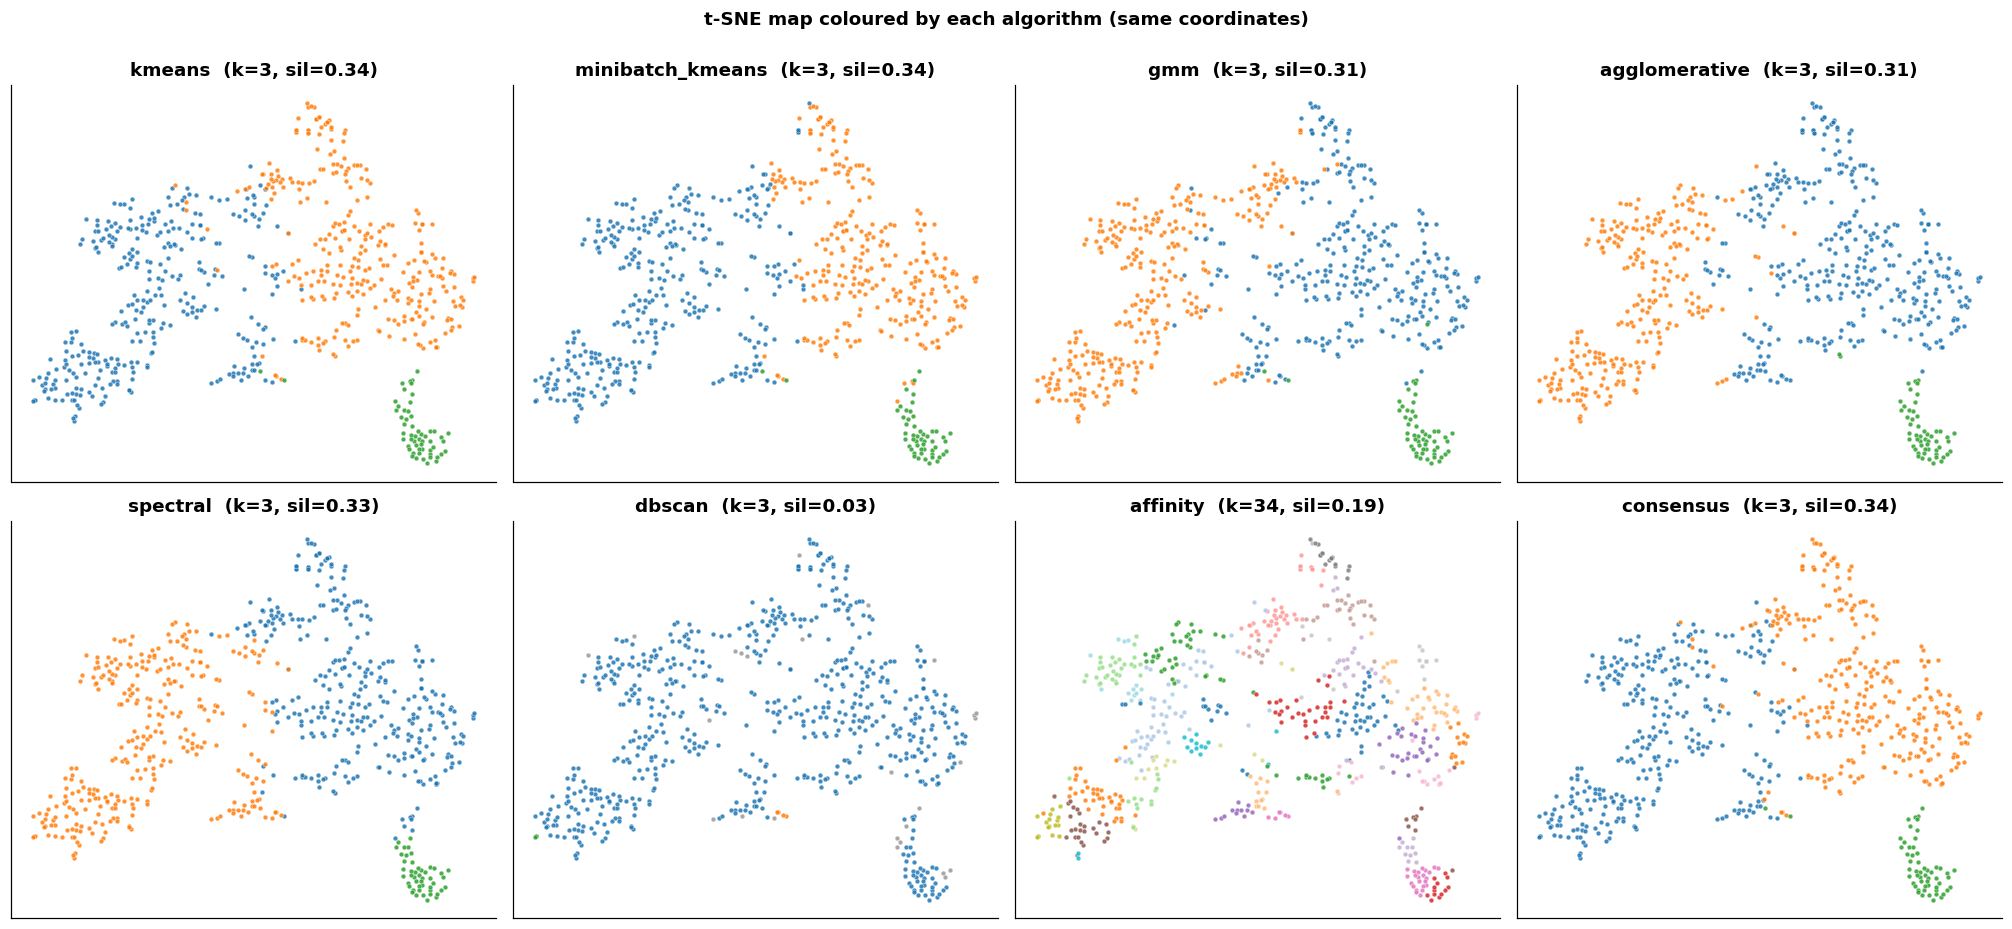

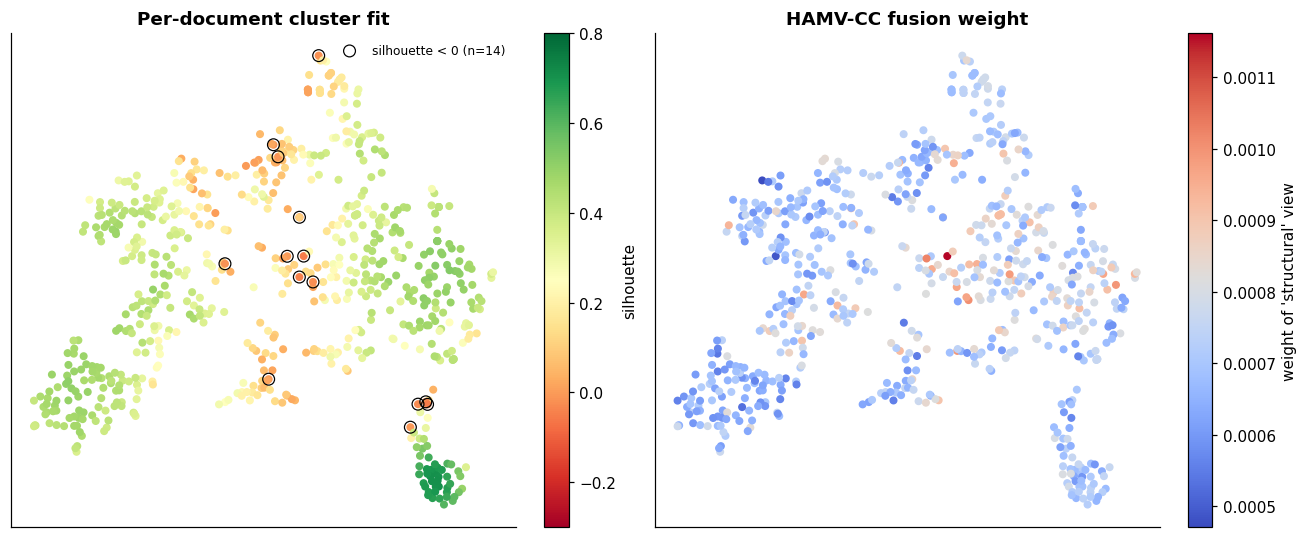

In [46]:
# 21G. Two-dimensional embeddings of the clustered space
EMB = {"PCA": PCA(n_components=2, random_state=SEED).fit_transform(X_CL)}
perp = float(min(30, max(5, (N_DOCS - 1) / 3)))
EMB["t-SNE"] = TSNE(n_components=2, perplexity=perp, init="pca", learning_rate="auto",
                    random_state=SEED).fit_transform(X_CL)
if CLUSTER_CFG["use_umap"]:
    try:
        import umap
        EMB["UMAP"] = umap.UMAP(n_neighbors=min(15, N_DOCS - 1), min_dist=0.1,
                                random_state=SEED).fit_transform(X_CL)
    except Exception as e:
        print("UMAP not used (pip install umap-learn to enable):", type(e).__name__)
pd.DataFrame({f"{k}_{ax}": v[:, i] for k, v in EMB.items() for i, ax in enumerate(["x", "y"])}).assign(
    cluster=FINAL_LABELS).to_csv(CL_DIR / "clustering_embedding_coordinates.csv", index=False)

def scatter_clusters(ax, Z, labels, title, annotate=True, s=18):
    pal_ = cluster_palette(labels)
    for u in sorted(set(labels.tolist())):
        m = labels == u
        ax.scatter(Z[m, 0], Z[m, 1], s=s, color=pal_[u], alpha=0.85, edgecolor="white", linewidth=0.3,
                   label=("noise" if u == -1 else f"C{u} (n={m.sum()})"))
        if annotate and u != -1:
            cx, cy = np.median(Z[m, 0]), np.median(Z[m, 1])
            ax.text(cx, cy, str(u), fontsize=10, fontweight="bold", ha="center", va="center",
                    bbox=dict(boxstyle="circle,pad=0.2", fc="white", ec=pal_[u], lw=1.5))
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)

fig, axes = plt.subplots(1, len(EMB), figsize=(6.2 * len(EMB), 5.4))
axes = np.atleast_1d(axes)
for ax, (name, Z) in zip(axes, EMB.items()):
    scatter_clusters(ax, Z, FINAL_LABELS, f"{name} - {FINAL_ALGO}, k={len(ids_final)}")
axes[-1].legend(frameon=False, fontsize=8, loc="center left", bbox_to_anchor=(1.0, 0.5))
fig.suptitle(f"Document clusters in the {CHOSEN_REP} space", fontweight="bold", y=1.02)
plt.tight_layout(); clsave("cl06_cluster_embeddings.png"); plt.show()

# Same t-SNE map under every algorithm
Z = EMB["t-SNE"]
n_alg = len(LABELS); ncols = 4; nrows = int(np.ceil(n_alg / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4.6 * ncols, 4.2 * nrows))
axes = np.array(axes).reshape(-1)
for ax, (a, l) in zip(axes, LABELS.items()):
    sc = summarize_labels(X_CL, l)
    scatter_clusters(ax, Z, l, f"{a}  (k={sc['n_clusters']}, sil={sc['silhouette']:.2f})", annotate=False, s=10)
for ax in axes[n_alg:]:
    ax.axis("off")
fig.suptitle("t-SNE map coloured by each algorithm (same coordinates)", fontweight="bold", y=1.0)
plt.tight_layout(); clsave("cl07_all_algorithms_tsne.png"); plt.show()

# Confidence / reliability overlays
n_pan = 2 + (1 if Y_TRUE is not None else 0)
fig, axes = plt.subplots(1, n_pan, figsize=(6 * n_pan, 5))
axes = np.atleast_1d(axes)
sc0 = axes[0].scatter(Z[:, 0], Z[:, 1], c=sil_s, cmap="RdYlGn", vmin=-0.3, vmax=0.8, s=18)
low = np.where(sil_s < 0)[0]
axes[0].scatter(Z[low, 0], Z[low, 1], s=60, facecolors="none", edgecolors="k", linewidths=0.8,
                label=f"silhouette < 0 (n={len(low)})")
axes[0].legend(frameon=False, fontsize=8); plt.colorbar(sc0, ax=axes[0], fraction=0.046, label="silhouette")
axes[0].set_title("Per-document cluster fit"); axes[0].set_xticks([]); axes[0].set_yticks([]); axes[0].grid(False)
if HAMV_REAL:
    w = HAMV_REAL["weights"][:, 0]
    sc1 = axes[1].scatter(Z[:, 0], Z[:, 1], c=w, cmap="coolwarm", s=18)
    plt.colorbar(sc1, ax=axes[1], fraction=0.046, label=f"weight of '{HAMV_REAL['view_names'][0]}' view")
    axes[1].set_title("HAMV-CC fusion weight")
else:
    sc1 = axes[1].scatter(Z[:, 0], Z[:, 1], c=margin, cmap="viridis", s=18)
    plt.colorbar(sc1, ax=axes[1], fraction=0.046, label="centroid margin")
    axes[1].set_title("Assignment margin (nearest vs 2nd-nearest centroid)")
axes[1].set_xticks([]); axes[1].set_yticks([]); axes[1].grid(False)
if Y_TRUE is not None:
    scatter_clusters(axes[2], Z, Y_TRUE, "Planted ground truth (synthetic fixture)", annotate=False)
plt.tight_layout(); clsave("cl08_confidence_overlays.png"); plt.show()


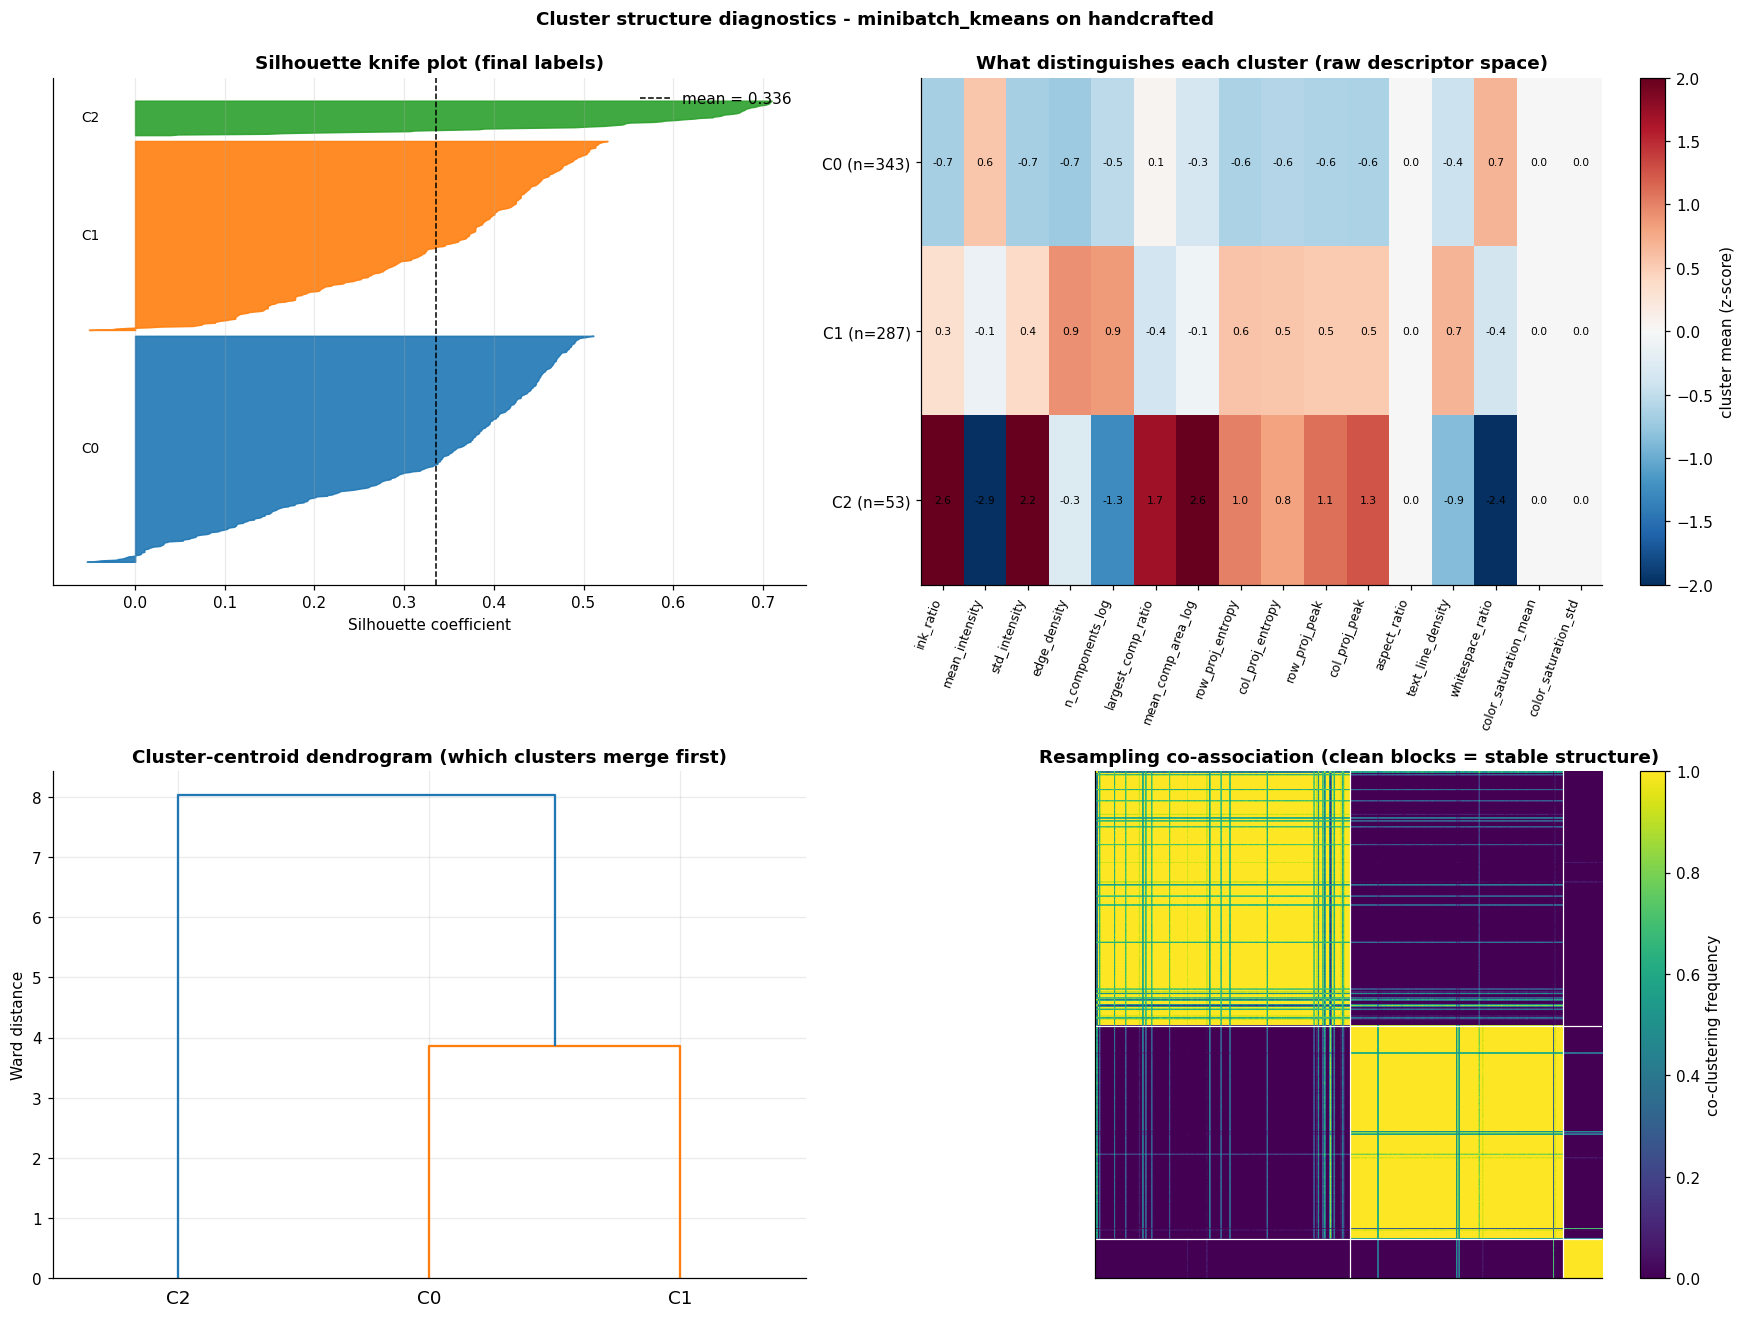

In [47]:
# 21H. Cluster structure diagnostics: silhouette knife, feature profiles, centroid dendrogram, co-association
from scipy.cluster.hierarchy import dendrogram

def coassociation(X, k, R=30, frac=0.80, seed=42):
    rng = np.random.RandomState(seed)
    n = len(X)
    co = np.zeros((n, n), dtype=np.float32); cnt = np.zeros((n, n), dtype=np.float32)
    for r in range(R):
        idx = rng.choice(n, size=max(k, int(frac * n)), replace=False)
        lab = KMeans(n_clusters=k, n_init=3, random_state=seed + r).fit_predict(X[idx])
        same = (lab[:, None] == lab[None, :]).astype(np.float32)
        co[np.ix_(idx, idx)] += same; cnt[np.ix_(idx, idx)] += 1
    return np.divide(co, cnt, out=np.zeros_like(co), where=cnt > 0)

K_EFF = max(2, len(ids_final))
pal = cluster_palette(FINAL_LABELS)
fig = plt.figure(figsize=(16, 12))
gs = fig.add_gridspec(2, 2)

# (a) silhouette knife plot
ax = fig.add_subplot(gs[0, 0])
y0 = 0
for u in ids_final:
    v = np.sort(sil_s[FINAL_LABELS == u])
    ax.fill_betweenx(np.arange(y0, y0 + len(v)), 0, v, color=pal[u], alpha=0.9)
    ax.text(-0.04, y0 + len(v) / 2, f"C{u}", ha="right", va="center", fontsize=9)
    y0 += len(v) + 8
if np.isfinite(sil_s).any():
    ax.axvline(np.nanmean(sil_s), color="k", ls="--", lw=1, label=f"mean = {np.nanmean(sil_s):.3f}")
ax.set_xlabel("Silhouette coefficient"); ax.set_yticks([]); ax.legend(frameon=False)
ax.set_title("Silhouette knife plot (final labels)")

# (b) z-scored feature profile per cluster
ax = fig.add_subplot(gs[0, 1])
mu, sd = PROFILE_X.mean(0), PROFILE_X.std(0)
sd = np.where(sd < 1e-12, 1.0, sd)
prof = np.vstack([(PROFILE_X[FINAL_LABELS == u].mean(0) - mu) / sd for u in ids_final]) if ids_final else np.zeros((1, 1))
im = ax.imshow(prof, aspect="auto", cmap="RdBu_r", vmin=-2, vmax=2)
ax.set_yticks(range(len(ids_final))); ax.set_yticklabels([f"C{u} (n={(FINAL_LABELS==u).sum()})" for u in ids_final])
ax.set_xticks(range(len(PROFILE_NAMES))); ax.set_xticklabels(PROFILE_NAMES, rotation=70, ha="right", fontsize=8)
if prof.shape[1] <= 16:
    for i in range(prof.shape[0]):
        for j in range(prof.shape[1]):
            ax.text(j, i, f"{prof[i, j]:.1f}", ha="center", va="center", fontsize=7)
plt.colorbar(im, ax=ax, fraction=0.046, label="cluster mean (z-score)")
ax.grid(False); ax.set_title("What distinguishes each cluster (raw descriptor space)")

# (c) dendrogram of cluster centroids
ax = fig.add_subplot(gs[1, 0])
if len(ids_final) >= 3:
    C = np.vstack([cent[u] for u in ids_final])
    Zl = linkage(C, method="ward")
    dendrogram(Zl, labels=[f"C{u}" for u in ids_final], ax=ax, color_threshold=0.7 * Zl[:, 2].max())
    ax.set_ylabel("Ward distance"); ax.set_title("Cluster-centroid dendrogram (which clusters merge first)")
else:
    ax.text(0.5, 0.5, "Need >= 3 clusters for a dendrogram", ha="center", va="center"); ax.axis("off")

# (d) consensus co-association heatmap, ordered by final cluster
ax = fig.add_subplot(gs[1, 1])
A = coassociation(X_CL, K_EFF, R=30, seed=SEED)
order = np.lexsort((np.arange(N_DOCS), np.where(FINAL_LABELS == -1, 10**6, FINAL_LABELS)))
im = ax.imshow(A[np.ix_(order, order)], cmap="viridis", vmin=0, vmax=1)
bounds = np.cumsum([(FINAL_LABELS == u).sum() for u in ids_final])
if not (FINAL_LABELS == -1).any():
    bounds = bounds[:-1]
for b in bounds:
    ax.axhline(b - 0.5, color="w", lw=0.8); ax.axvline(b - 0.5, color="w", lw=0.8)
plt.colorbar(im, ax=ax, fraction=0.046, label="co-clustering frequency")
ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
ax.set_title("Resampling co-association (clean blocks = stable structure)")
fig.suptitle(f"Cluster structure diagnostics - {FINAL_ALGO} on {CHOSEN_REP}", fontweight="bold", y=0.995)
plt.tight_layout(); clsave("cl09_structure_diagnostics.png"); plt.show()
COASSOC = A


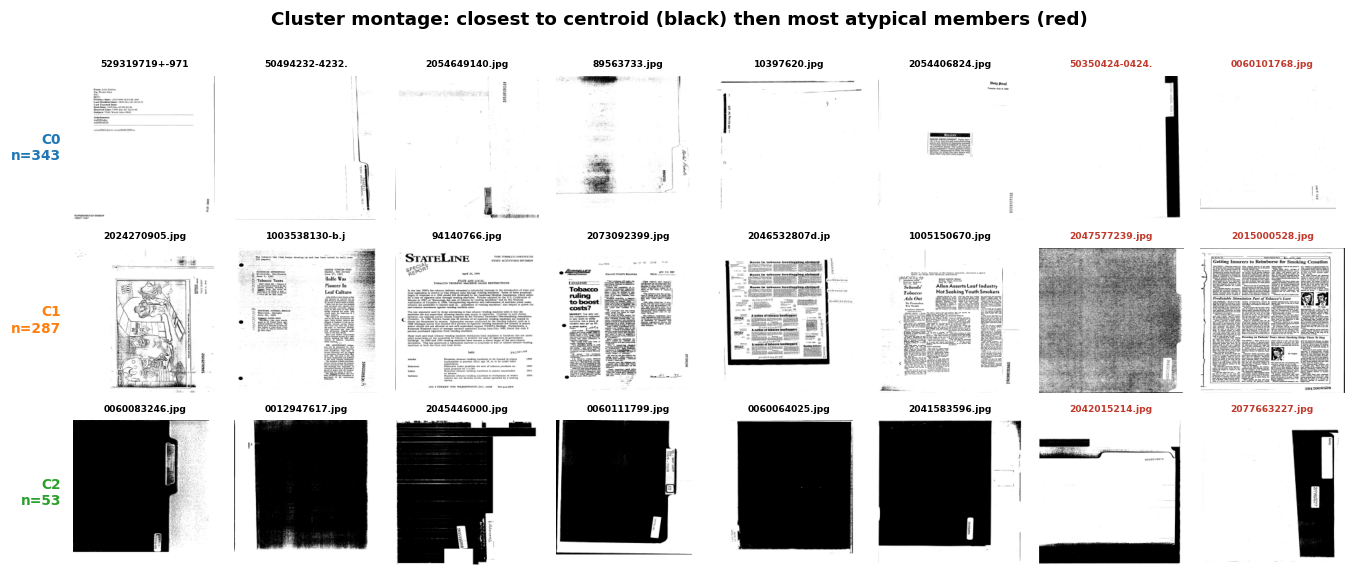

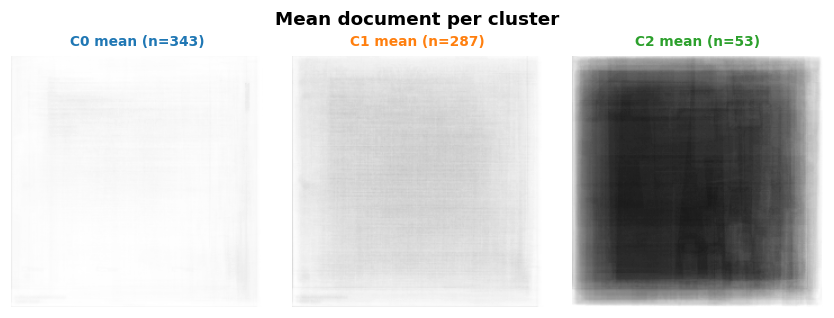

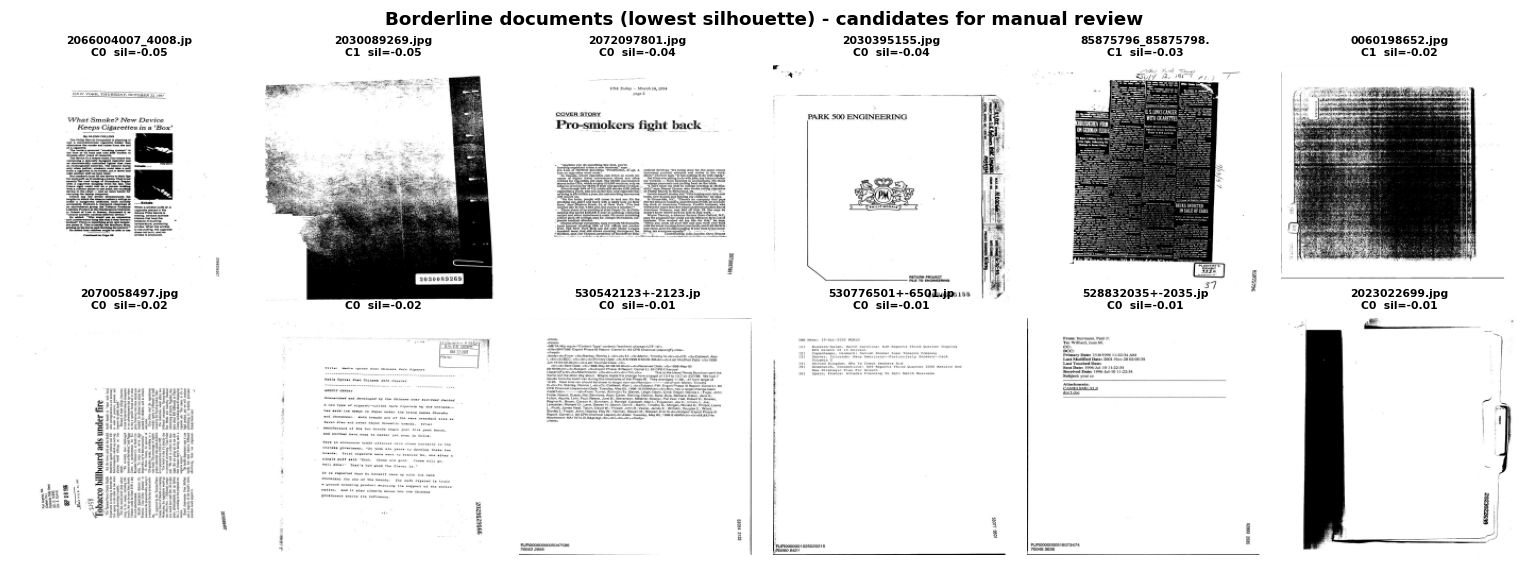

In [48]:
# 21I. What the clusters actually look like: image montage, mean images, borderline documents
if not ARCHIVE_MODE or DOC_IMAGES is None:
    print("Image montage skipped (synthetic mode has no document images).")
else:
    show_ids = sorted(ids_final, key=lambda u: -(FINAL_LABELS == u).sum())[:CLUSTER_CFG["max_montage_clusters"]]
    nm = CLUSTER_CFG["n_montage"]
    fig, axes = plt.subplots(len(show_ids), nm, figsize=(1.55 * nm, 1.75 * len(show_ids)), squeeze=False)
    for r, u in enumerate(show_ids):
        members = np.where(FINAL_LABELS == u)[0]
        order_m = members[np.argsort(dist_to_centroid[members])]
        picks = list(order_m[:max(1, nm - 2)]) + (list(order_m[-2:]) if len(order_m) > nm else [])
        picks = picks[:nm]
        for c in range(nm):
            ax = axes[r, c]; ax.axis("off")
            if c < len(picks):
                i = picks[c]
                ax.imshow(DOC_IMAGES[i], cmap="gray" if DOC_IMAGES[i].ndim == 2 else None)
                far = (c >= nm - 2) and len(order_m) > nm
                ax.set_title(DOC_NAMES[i][:14], fontsize=6, color="#c0392b" if far else "black")
                if far:
                    for sp in ax.spines.values():
                        sp.set_visible(True); sp.set_edgecolor("#c0392b"); sp.set_linewidth(2)
        axes[r, 0].text(-0.08, 0.5, f"C{u}\nn={len(members)}", transform=axes[r, 0].transAxes,
                        ha="right", va="center", fontsize=9, fontweight="bold", color=pal[u])
    fig.suptitle("Cluster montage: closest to centroid (black) then most atypical members (red)",
                 fontweight="bold", y=1.0)
    plt.tight_layout(); clsave("cl10_cluster_montage.png", dpi=170); plt.show()

    # Mean image per cluster (shows the dominant layout)
    ncol = min(6, len(show_ids)); nrow = int(np.ceil(len(show_ids) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(2.6 * ncol, 2.9 * nrow), squeeze=False)
    for ax in axes.reshape(-1):
        ax.axis("off")
    for ax, u in zip(axes.reshape(-1), show_ids):
        stack = np.stack([cv2.cvtColor(DOC_IMAGES[i], cv2.COLOR_RGB2GRAY) if DOC_IMAGES[i].ndim == 3
                          else DOC_IMAGES[i] for i in np.where(FINAL_LABELS == u)[0]]).astype(np.float32)
        ax.imshow(stack.mean(0), cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"C{u} mean (n={len(stack)})", fontsize=9, color=pal[u])
    fig.suptitle("Mean document per cluster", fontweight="bold")
    plt.tight_layout(); clsave("cl11_cluster_mean_images.png"); plt.show()

    # Most borderline documents (lowest silhouette)
    cand = np.argsort(np.where(np.isnan(sil_s), 9, sil_s))[:12]
    fig, axes = plt.subplots(2, 6, figsize=(14, 5.2))
    for ax, i in zip(axes.reshape(-1), cand):
        ax.imshow(DOC_IMAGES[i]); ax.axis("off")
        ax.set_title(f"{DOC_NAMES[i][:18]}\nC{FINAL_LABELS[i]}  sil={sil_s[i]:.2f}", fontsize=7)
    fig.suptitle("Borderline documents (lowest silhouette) - candidates for manual review", fontweight="bold")
    plt.tight_layout(); clsave("cl12_borderline_documents.png"); plt.show()


,cluster,bootstrap_jaccard,status
0,0,0.922,stable (>=0.75)
1,1,0.906,stable (>=0.75)
2,2,0.928,stable (>=0.75)


Mean ARI of 80% subsamples vs full labelling: 0.852 +/- 0.099 over 20 runs


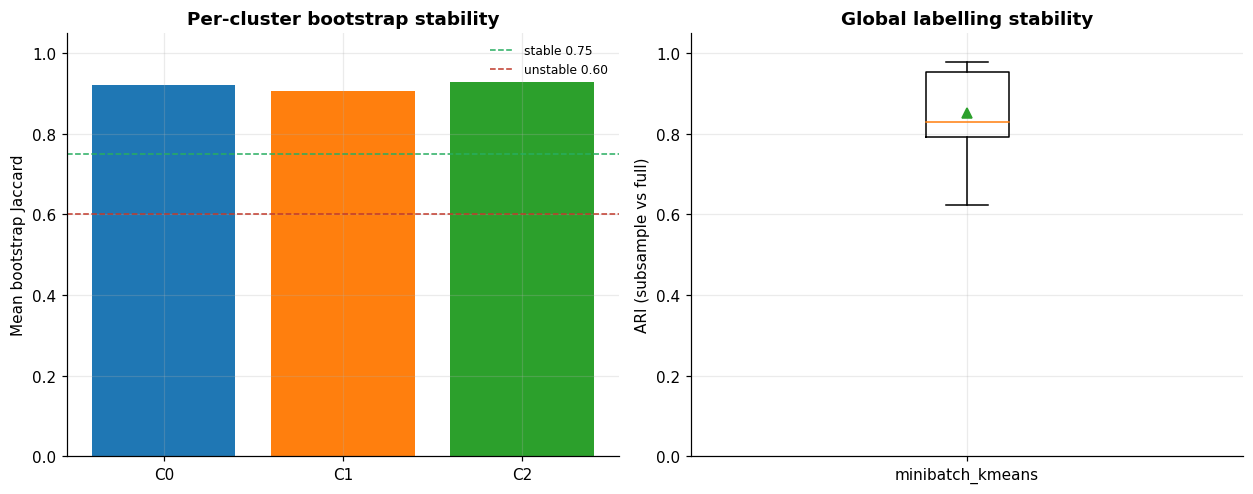


Duplicate SHA-256 groups: 8 | split across clusters: 0
OK: every duplicate group stays together.


In [49]:
# 21J. Robustness audit: bootstrap cluster stability, duplicate consistency, external-label check
def bootstrap_cluster_stability(X, lab_ref, algo, k, B, frac, seed):
    rng = np.random.RandomState(seed)
    n = len(X)
    ids = [u for u in np.unique(lab_ref) if u != -1]
    J = {u: [] for u in ids}
    aris = []
    for b in range(B):
        idx = np.sort(rng.choice(n, size=int(frac * n), replace=False))
        lab_b = np.asarray(run_clustering(X[idx], algo, k=k, seed=seed + b)[0])
        aris.append(adjusted_rand_score(lab_ref[idx], lab_b))
        for u in ids:
            ref = lab_ref[idx] == u
            best = 0.0
            for v in np.unique(lab_b):
                if v == -1:
                    continue
                m = lab_b == v
                union = (ref | m).sum()
                best = max(best, (ref & m).sum() / union if union else 0.0)
            J[u].append(best)
    return {u: float(np.mean(v)) for u, v in J.items()}, aris

B_RUNS = CLUSTER_CFG["bootstrap_runs"] if FINAL_ALGO != "consensus" else min(8, CLUSTER_CFG["bootstrap_runs"])
JACC, BOOT_ARI = bootstrap_cluster_stability(X_CL, FINAL_LABELS, FINAL_ALGO, K_FINAL, B_RUNS,
                                             CLUSTER_CFG["bootstrap_fraction"], SEED)
BOOT_DF = pd.DataFrame({"cluster": list(JACC), "bootstrap_jaccard": list(JACC.values())})
BOOT_DF["status"] = pd.cut(BOOT_DF["bootstrap_jaccard"], [-1, 0.6, 0.75, 1.01],
                           labels=["unstable (<0.60)", "indicative (0.60-0.75)", "stable (>=0.75)"])
BOOT_DF.to_csv(CL_DIR / "clustering_bootstrap_stability.csv", index=False)
display(BOOT_DF.round(3))
print(f"Mean ARI of {int(CLUSTER_CFG['bootstrap_fraction']*100)}% subsamples vs full labelling: "
      f"{np.mean(BOOT_ARI):.3f} +/- {np.std(BOOT_ARI):.3f} over {B_RUNS} runs")

has_ext = Y_TRUE is not None
fig, axes = plt.subplots(1, 3 if has_ext else 2, figsize=(16 if has_ext else 11.5, 4.6))
axes = np.atleast_1d(axes)
axes[0].bar([f"C{u}" for u in BOOT_DF["cluster"]], BOOT_DF["bootstrap_jaccard"],
            color=[pal[u] for u in BOOT_DF["cluster"]])
axes[0].axhline(0.75, color="#27ae60", ls="--", lw=1, label="stable 0.75")
axes[0].axhline(0.60, color="#c0392b", ls="--", lw=1, label="unstable 0.60")
axes[0].set_ylim(0, 1.05); axes[0].set_ylabel("Mean bootstrap Jaccard"); axes[0].legend(frameon=False, fontsize=8)
axes[0].set_title("Per-cluster bootstrap stability")
axes[1].boxplot(BOOT_ARI, vert=True, showmeans=True); axes[1].set_xticks([1]); axes[1].set_xticklabels([FINAL_ALGO])
axes[1].set_ylabel("ARI (subsample vs full)"); axes[1].set_ylim(0, 1.05); axes[1].set_title("Global labelling stability")
if has_ext:
    cm = confusion_matrix(Y_TRUE, FINAL_LABELS)
    rr, cc = linear_sum_assignment(-cm)
    col_order = list(cc) + [c for c in range(cm.shape[1]) if c not in cc]
    cm = cm[:, col_order]
    im = axes[2].imshow(cm, cmap="Blues")
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            axes[2].text(j, i, cm[i, j], ha="center", va="center", fontsize=9)
    axes[2].set_xlabel("Predicted cluster (Hungarian-ordered)"); axes[2].set_ylabel("True class")
    axes[2].grid(False); axes[2].set_title("Confusion vs planted labels")
    print("External metrics (synthetic fixture only):", evaluate_labels(FINAL_LABELS, Y_TRUE))
plt.tight_layout(); clsave("cl13_robustness_audit.png"); plt.show()

# Exact-duplicate consistency: byte-identical files must receive the same cluster.
if ARCHIVE_MODE and (ASSIGN["sha256"] != "").any():
    g = ASSIGN[ASSIGN["sha256"] != ""].groupby("sha256")["cluster"].agg(["size", "nunique"])
    g = g[g["size"] > 1]
    split = int((g["nunique"] > 1).sum())
    print(f"\nDuplicate SHA-256 groups: {len(g)} | split across clusters: {split}")
    if split:
        print("WARNING: identical files were separated - check stochastic components / preprocessing determinism.")
        display(g[g["nunique"] > 1])
    else:
        print("OK: every duplicate group stays together.")


In [50]:
# 21K. Per-cluster summary, written report, optional folder export
rows = []
Zprof = (PROFILE_X - PROFILE_X.mean(0)) / np.where(PROFILE_X.std(0) < 1e-12, 1.0, PROFILE_X.std(0))
for u in ids_final:
    m = np.where(FINAL_LABELS == u)[0]
    nearest = m[np.argsort(dist_to_centroid[m])][:5]
    zc = Zprof[m].mean(0)
    top = np.argsort(-np.abs(zc))[:3]
    rows.append({
        "cluster": u, "size": len(m), "share": len(m) / N_DOCS,
        "mean_silhouette": float(np.nanmean(sil_s[m])),
        "bootstrap_jaccard": JACC.get(u, np.nan),
        "typical_documents": "; ".join(DOC_NAMES[i] for i in nearest),
        "distinguishing_features": ", ".join(f"{PROFILE_NAMES[j]}({zc[j]:+.2f})" for j in top),
    })
if (FINAL_LABELS == -1).any():
    rows.append({"cluster": -1, "size": int((FINAL_LABELS == -1).sum()), "share": float((FINAL_LABELS == -1).mean()),
                 "mean_silhouette": np.nan, "bootstrap_jaccard": np.nan, "typical_documents": "", "distinguishing_features": "noise"})
SUMMARY = pd.DataFrame(rows)
SUMMARY.to_csv(CL_DIR / "clustering_summary.csv", index=False)
display(SUMMARY.round(3))

report = f"""# HAMV-CC archive clustering report

Generated: {datetime.now().isoformat(timespec='seconds')}
Mode: {DATA_MODE} | documents: {N_DOCS}
Representation: {CHOSEN_REP} (dim={X_CL.shape[1]}) | k selection: {CLUSTER_CFG['k_mode']} -> k={K_FINAL}
Final algorithm: {FINAL_ALGO} | clusters found: {len(ids_final)} | noise: {(FINAL_LABELS == -1).mean():.1%}
Mean silhouette: {np.nanmean(sil_s):.4f} | bootstrap ARI: {np.mean(BOOT_ARI):.3f}

## Representation comparison
{REP_DF.round(4).to_string(index=False)}

## Algorithm comparison
{ALGO_DF.round(4).to_string(index=False)}

## Cluster summary
{SUMMARY.round(3).to_string(index=False)}

## Evidence boundary
Internal metrics are geometric diagnostics, not semantic ground truth. Auto-selection of representation/algorithm is a
convenience ranking. External-label metrics are only meaningful where independent labels exist.
Configuration: {json.dumps(CLUSTER_CFG, default=str)}
"""
(CL_DIR / "clustering_report.md").write_text(report, encoding="utf-8")
print("Wrote", CL_DIR / "clustering_report.md")

if CLUSTER_CFG["export_cluster_folders"] and ARCHIVE_MODE:
    import shutil
    dest_root = Path(OUT_DIR) / "clustering_export"
    for i, (p, l) in enumerate(zip(DOC_PATHS, FINAL_LABELS)):
        d = dest_root / ("noise" if l == -1 else f"cluster_{l:02d}")
        d.mkdir(parents=True, exist_ok=True)
        shutil.copy2(p, d / f"{i:05d}_{Path(p).name}")
    print("Copied documents into", dest_root)

print("\nFigures written to", CL_FIG)
for f in sorted(CL_FIG.glob("cl*.png")):
    print("  ", f.name)
if "index_csv_outputs" in globals():
    display(index_csv_outputs())


,cluster,size,share,mean_silhouette,bootstrap_jaccard,typical_documents,distinguishing_features
0,0,343,0.502,0.305,0.922,529319719+-9719.jpg; 50494232-4232.jpg; 205464...,"edge_density(-0.72), whitespace_ratio(+0.68), ..."
1,1,287,0.420,0.333,0.906,2024270905.jpg; 1003538130-b.jpg; 94140766.jpg...,"edge_density(+0.91), n_components_log(+0.85), ..."
2,2,53,0.078,0.551,0.928,0060083246.jpg; 0012947617.jpg; 2045446000.jpg...,"mean_intensity(-2.89), mean_comp_area_log(+2.6..."


Wrote c:\Users\Debmalya Ray\OneDrive\Desktop\NEW_MODEL\NEW_FOLDER_03_10_2026\hamvcc_runs\20261004_205633\clustering_report.md

Figures written to c:\Users\Debmalya Ray\OneDrive\Desktop\NEW_MODEL\NEW_FOLDER_03_10_2026\hamvcc_runs\20261004_205633\figures
   cl01_hamvcc_training_and_weights.png
   cl02_representation_comparison.png
   cl03_k_diagnostics.png
   cl04_algorithm_comparison.png
   cl05_agreement_and_sizes.png
   cl06_cluster_embeddings.png
   cl07_all_algorithms_tsne.png
   cl08_confidence_overlays.png
   cl09_structure_diagnostics.png
   cl10_cluster_montage.png
   cl11_cluster_mean_images.png
   cl12_borderline_documents.png
   cl13_robustness_audit.png


,file,rows,columns
0,clustering_algorithm_results.csv,8,"[algorithm, seconds, seed_stability_ARI, n_clu..."
1,clustering_assignments.csv,683,"[doc_index, name, path, cluster, final_algorit..."
2,clustering_bootstrap_stability.csv,3,"[cluster, bootstrap_jaccard, status]"
3,clustering_embedding_coordinates.csv,683,"[PCA_x, PCA_y, t-SNE_x, t-SNE_y, cluster]"
4,clustering_hamvcc_history.csv,150,"[instance, cross_view, cluster_consistency, en..."
5,clustering_k_diagnostics.csv,19,"[k, silhouette, ch, db, sil_mean, ch_mean, db_..."
6,clustering_representation_comparison.csv,4,"[representation, dim, k_majority, k_stability,..."
7,clustering_ssl_history.csv,30,"[epoch, sigma, loss]"
8,clustering_summary.csv,3,"[cluster, size, share, mean_silhouette, bootst..."
9,evidence_ledger_index.csv,2,"[file, rows, columns]"


### How to read the clustering figures

- **cl02 / cl04** - compare representations and algorithms. Silhouette and Davies-Bouldin are geometric; a high value means
  compact, separated groups in the feature space, not necessarily meaningful document types.
- **cl03** - if the majority-vote k and the stability-aware k disagree, treat k as uncertain and inspect both.
- **cl06 / cl07 / cl08** - t-SNE/UMAP distances between far-apart clusters are not meaningful; use them for local grouping only.
- **cl09** - clean diagonal blocks in the co-association matrix and bootstrap Jaccard >= 0.75 indicate stable clusters.
- **cl10-cl12** - the human check. Read the montage rows before trusting any label; borderline documents are listed in the CSV.
- **cl13** - clusters with Jaccard < 0.60 should not be reported as findings.

Everything is regenerated from `CLUSTER_CFG`; to compare settings, change one field and re-run 21A onward.
